# FoldedVision AI — 최종 코드
수업의 데이터 확인 → 전처리 → 모델 구성 → compile → fit → 평가 순서를 따른다.
1112_김현모_0.8045.ipynb의 단계별 설명과 05.ipynb의 CNN을 출발점으로 삼았다.
추가 개념은 **검증 데이터, BatchNormalization, 클래스 불균형, U-Net**이다.

**데이터로 말할 수 있는 범위:** 정상 라벨이 확인되지 않으면 정상/불량 판정을 하지 않는다.
결함 유형 분류의 Softmax는 이미 결함이 있는 표본 안에서의 유형 점수다.
정상일 확률이나 불량일 확률로 해석할 수 없다.

## 실행 안내
- 앞부분: Ring 3종 결함 유형 분류와 시연. 최종 평가 80.95%.
- 마지막 베어링 절: 다운로드한 엔진 베어링 설치 상태 16종. 내부 검증 94.81%, 최종 평가 57.21%.
- 베어링만 실행하려면 처음 settings/environment/io 셀과 bearing_* 셀을 실행한다.
- 과거 미채택 Ring 추가 실험 PART 10~12는 최종 실행에서 제외했고,
  원래 코드·가중치·결과는 `archive/2026-11-19_before_cleanup.zip`에 보관했다.
- 작업 기억과 보존 규칙은 `AGENTS.md`, 전체 사용 안내는 `README.md` 참조.


In [1]:
# PART 01. 실행 설정 — 수정할 값은 이 셀에 모은다.
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("OMP_NUM_THREADS", "4")
from pathlib import Path
DATASET_NAME = "Ring"
IMAGE_SIZE = 256
BATCH_SIZE = 16
SEED = 42
RUN_MODE = os.environ.get("RING_RUN_MODE", "full")
TRAIN_IMPROVED_CNN = True
TRAIN_UNET = True
TRAIN_AUTOENCODER = False
USE_SAVED_MODELS = True
LAUNCH_UI = False
TARGET_RECALL = 0.95
MIN_LOCALIZATION_VALID_DICE = 0.10  # 시연에서 마스크를 제공할 최소 검증 품질
BASELINE_EPOCHS = 20 if RUN_MODE == "full" else 2
CNN_EPOCHS = 24 if RUN_MODE == "full" else 2
UNET_EPOCHS = 12 if RUN_MODE == "full" else 2
assert RUN_MODE in ("quick", "full")
assert IMAGE_SIZE >= 64 and IMAGE_SIZE % 8 == 0
project_start = Path.cwd().resolve()
PROJECT_ROOT = next((folder for folder in (project_start, *project_start.parents)
                     if (folder / "requirements-lock.txt").is_file()
                     and (folder / "AGENTS.md").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the FoldedVision_AI project.")
OUT = PROJECT_ROOT / "outputs"
MODELS = PROJECT_ROOT / "models"
if RUN_MODE == "quick":
    OUT = OUT / "quick"
    MODELS = MODELS / "quick"
for folder in [MODELS, OUT / "figures", OUT / "metrics",
               OUT / "predictions", OUT / "integration", PROJECT_ROOT / "data/processed"]:
    folder.mkdir(parents=True, exist_ok=True)
print("실행 모드:", RUN_MODE, "| 이미지 크기:", IMAGE_SIZE)

# 새 요청: 다운로드한 베어링 16종 자료 별도 학습
BR_IMAGE_SIZE = 192
BR_BATCH_SIZE = 32
BR_SEED = 42
BR_EPOCHS = 70 if RUN_MODE == "full" else 2
LAUNCH_BEARING_UI = False


실행 모드: full | 이미지 크기: 256


In [2]:
# 라이브러리와 CPU/GPU 확인
import sys, json, tarfile, hashlib, time, shutil
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    roc_curve, roc_auc_score, average_precision_score)
from IPython.display import display
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass
plt.rcParams["font.family"] = "Malgun Gothic" if sys.platform == "win32" else "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
print("Python:", sys.version.split()[0], "TensorFlow:", tf.__version__)
print("사용 가능한 GPU:", tf.config.list_physical_devices("GPU"))

Python: 3.11.9 TensorFlow: 2.15.0
사용 가능한 GPU: []


In [3]:
# JSON과 그림 저장 — NaN 대신 null을 사용하여 다른 팀도 읽을 수 있게 한다.
def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2,
                                    allow_nan=False), encoding="utf-8")
def save_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()
def read_rgb(path):
    # Windows 한글 경로도 읽을 수 있도록 imdecode를 사용한다.
    bgr = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"이미지를 읽을 수 없습니다: {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

## PART 01. 데이터 준비와 라벨 검증
inference를 정상 데이터로 간주하지 않는다. SHA-256 중복 검사 후 같은 분할을 재현한다.

In [4]:
# Ring만 찾는다. 다른 부품 데이터는 변경하지 않는다.
def find_ring():
    for folder in [PROJECT_ROOT / "data/raw/Ring", PROJECT_ROOT / "data/Ring", PROJECT_ROOT / "Ring"]:
        if (folder / "train/_annotations.coco.json").is_file():
            return folder
    searches = [PROJECT_ROOT, PROJECT_ROOT / "data", PROJECT_ROOT / "data/archives",
                PROJECT_ROOT / "data/raw", Path.home() / "Downloads"]
    archive = next((p / "Ring.tar.gz" for p in searches if (p / "Ring.tar.gz").is_file()), None)
    if archive is None:
        raise FileNotFoundError("Ring.tar.gz를 data/archives/에 넣어 주세요.")
    target = (PROJECT_ROOT / "data/raw").resolve()
    target.mkdir(parents=True, exist_ok=True)
    with tarfile.open(archive, "r:gz") as tar:
        for member in tar.getmembers():
            relative = Path(member.name)
            destination = (target / relative).resolve()
            if (relative.is_absolute() or not destination.is_relative_to(target)
                or not relative.parts or relative.parts[0] != "Ring"):
                raise ValueError(f"안전하지 않은 압축 경로: {member.name}")
            if member.issym() or member.islnk() or not (member.isfile() or member.isdir()):
                raise ValueError(f"허용하지 않는 압축 항목: {member.name}")
            if relative.name.startswith("._") or "__MACOSX" in relative.parts:
                continue
            if member.isdir():
                destination.mkdir(parents=True, exist_ok=True)
            elif not destination.exists():
                destination.parent.mkdir(parents=True, exist_ok=True)
                with tar.extractfile(member) as src, destination.open("wb") as dst:
                    shutil.copyfileobj(src, dst)
    return target / "Ring"
DATA_ROOT = find_ring()
print("원본 데이터:", DATA_ROOT)

원본 데이터: C:\Users\kdt66\Desktop\FoldedVision_AI\data\raw\Ring


In [5]:
# COCO의 images, annotations, categories를 실제로 연결한다.
coco = {}
records, objects = [], []
annotations_by_key = {}
for official_split in ["train", "val", "inference"]:
    document = json.loads((DATA_ROOT / official_split / "_annotations.coco.json").read_text(encoding="utf-8"))
    coco[official_split] = document
    by_image = defaultdict(list)
    for annotation in document.get("annotations", []):
        by_image[annotation["image_id"]].append(annotation)
    for image in document["images"]:
        image_path = (DATA_ROOT / official_split / image["file_name"]).resolve()
        if not image_path.is_relative_to(DATA_ROOT.resolve()):
            raise ValueError("COCO 이미지 경로가 데이터 폴더 밖을 가리킵니다.")
        rgb = read_rgb(image_path)
        if rgb.shape[:2] != (image["height"], image["width"]):
            raise ValueError("COCO 크기와 실제 이미지 크기가 다릅니다.")
        key = f"{official_split}:{image['id']}"
        anns = by_image[image["id"]]
        annotations_by_key[key] = anns
        records.append(dict(image_id=key, path=str(image_path),
            official_split=official_split, width=rgb.shape[1], height=rgb.shape[0],
            extension=image_path.suffix.lower(), n_defects=len(anns),
            category_ids=sorted({a["category_id"] for a in anns}),
            sha256=hashlib.sha256(image_path.read_bytes()).hexdigest()))
        for a in anns:
            x, y, w, h = a["bbox"]
            objects.append(dict(image_id=key, official_split=official_split,
                category_id=a["category_id"], cx=(x+w/2)/rgb.shape[1],
                cy=(y+h/2)/rgb.shape[0], box_area=w*h/(rgb.shape[0]*rgb.shape[1]),
                polygon_area=a.get("area"), has_polygon=isinstance(a.get("segmentation"),list)
                and bool(a["segmentation"])))
images = pd.DataFrame(records)
annotations = pd.DataFrame(objects)
categories = sorted(coco["train"]["categories"], key=lambda c: c["id"])
CLASS_NAMES = [c["name"] for c in categories]
CLASS_KO = {"t_contamination": "오염", "t_scratch": "긁힘", "unfinished_surface": "표면 미가공"}
category_to_label = {c["id"]: i for i, c in enumerate(categories)}
print("결함 유형:", [(name, CLASS_KO.get(name, "원문 확인 필요")) for name in CLASS_NAMES])
display(images.groupby("official_split").agg(
    이미지수=("image_id","size"), 어노테이션없는이미지=("n_defects",lambda s:int((s==0).sum()))))

결함 유형: [('t_contamination', '오염'), ('t_scratch', '긁힘'), ('unfinished_surface', '표면 미가공')]


,이미지수,어노테이션없는이미지
official_split,,
inference,464,464
train,45,0
val,42,0


In [6]:
# 공식 카드: inference는 테스트+미사용 이미지이며 정답이 없다.
SOURCE_URL = "https://huggingface.co/datasets/VISION-Workshop/VISION-Datasets"
LABEL_REASON = ("공식 train/val의 모든 이미지에 결함 어노테이션이 있다. "
    "inference에는 정답이 없으므로 정상으로 사용할 수 없다. "
    "검증된 정상 표본이 없어 이진 분류와 제조 불량 감소율은 평가 불가.")
BINARY_SUPPORTED = False
labeled = images[images.official_split.isin(["train","val"])].copy()
assert labeled.category_ids.map(len).eq(1).all(), "다중 라벨 데이터: 별도 설계가 필요합니다."
labeled["label"] = labeled.category_ids.map(lambda ids: category_to_label[ids[0]])
labeled["defect_type"] = labeled.label.map(dict(enumerate(CLASS_NAMES)))
print(LABEL_REASON)
display(pd.crosstab(labeled.defect_type, labeled.official_split))
audit = dict(dataset="Ring", total_images=len(images), labeled_images=len(labeled),
    verified_normal_images=0, annotated_defect_images=len(labeled),
    unlabeled_images=int((images.official_split=="inference").sum()),
    class_names=CLASS_NAMES, source_url=SOURCE_URL, binary_supported=False,
    label_reason=LABEL_REASON, exact_duplicate_extra_images=int(images.sha256.duplicated().sum()),
    extensions=images.extension.value_counts().to_dict(),
    resolutions=images.groupby(["width","height"]).size().reset_index(name="count").to_dict("records"),
    bbox_count=len(annotations), polygon_count=int(annotations.has_polygon.sum()),
    source_note="공식 polygon은 원본 bbox를 보완한 라벨이며 정밀 제조 계측 정답이 아니다.")
save_json(OUT / "metrics/data_audit.json", audit)
images.drop(columns=["category_ids"]).to_csv(OUT / "metrics/image_inventory.csv",index=False)

공식 train/val의 모든 이미지에 결함 어노테이션이 있다. inference에는 정답이 없으므로 정상으로 사용할 수 없다. 검증된 정상 표본이 없어 이진 분류와 제조 불량 감소율은 평가 불가.


official_split,train,val
defect_type,,
t_contamination,13,15
t_scratch,25,23
unfinished_surface,7,4


In [7]:
# 공식 val은 최종 평가로 재지정. 공식 train 안에서만 학습/검증한다.
holdout = labeled[labeled.official_split=="val"].drop_duplicates("sha256").copy()
pool = labeled[(labeled.official_split=="train")
               & ~labeled.sha256.isin(holdout.sha256)].drop_duplicates("sha256").copy()
train, valid = train_test_split(pool, test_size=0.25, random_state=SEED, stratify=pool.label)
train, valid, holdout = [d.reset_index(drop=True) for d in (train, valid, holdout)]
for left, right in [(train, valid), (train, holdout), (valid, holdout)]:
    assert set(left.sha256).isdisjoint(right.sha256)
manifest = pd.concat([d.assign(split=name) for name,d in
                      [("train",train),("validation",valid),("holdout",holdout)]])
manifest.drop(columns=["category_ids"]).to_csv(OUT / "metrics/split_manifest.csv",index=False)
DATA_SIGNATURE = hashlib.sha256(manifest[["image_id","sha256","split"]]
    .to_csv(index=False).encode()).hexdigest()
print("학습 / 검증 / 최종 평가:", len(train), len(valid), len(holdout))
print("동일 바이트 중복은 분리 간 제거. 유사 촬영 이미지의 잔여 상관은 한계로 남는다.")

학습 / 검증 / 최종 평가: 33 12 42
동일 바이트 중복은 분리 간 제거. 유사 촬영 이미지의 잔여 상관은 한계로 남는다.


## PART 03. 입력 준비
0~255 픽셀을 0~1로 변환한다. 표 형태 실습의 MinMaxScaler와 달리 고정된 255로 나눈다.

In [8]:
# PART 03. OpenCV 전처리 — 색상 정보와 작은 결함을 보존한다.
def preprocess(rgb, method="rgb", size=IMAGE_SIZE):
    image = rgb.copy()
    if method == "clahe":
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        lab[:,:,0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(lab[:,:,0])
        image = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    elif method == "denoise":
        image = cv2.GaussianBlur(image, (3,3), 0)
    elif method != "rgb":
        raise ValueError(f"지원하지 않는 전처리: {method}")
    # 전체 프레임을 유지하여 ROI 밖의 결함이 잘리는 것을 피한다.
    image = cv2.resize(image, (size,size), interpolation=cv2.INTER_AREA)
    return image.astype("float32") / 255.0
def load_xy(frame, method="rgb"):
    x = np.stack([preprocess(read_rgb(p), method) for p in frame.path])
    return x, frame.label.to_numpy(dtype="int32")


In [9]:
X_train, y_train = load_xy(train)
X_valid, y_valid = load_xy(valid)
print("입력:", X_train.shape, "| 정답:", y_train.shape)

입력: (33, 256, 256, 3) | 정답: (33,)


In [10]:
# 수업의 Sequential / Conv2D / Pooling / Dense를 확장한다.
def build_cnn(improved=False):
    model = keras.Sequential(name="ring_improved" if improved else "ring_baseline")
    model.add(keras.Input(shape=(IMAGE_SIZE,IMAGE_SIZE,3)))
    if improved:
        # fit 중에만 증강한다. 검증/평가/추론에는 증강하지 않는다.
        model.add(layers.RandomFlip("horizontal_and_vertical", seed=SEED))
        model.add(layers.RandomRotation(0.04, fill_mode="reflect", seed=SEED))
    for filters in [32,64,128]:
        model.add(layers.Conv2D(filters, 3, padding="same",
                               activation=None if improved else "relu"))
        if improved:
            model.add(layers.BatchNormalization())
            model.add(layers.Activation("relu"))
            if filters == 32:
                model.add(layers.Conv2D(filters,3,padding="same",activation="relu"))
        if filters != 128:
            model.add(layers.MaxPooling2D())
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(64,activation="relu"))
    if improved:
        model.add(layers.Dropout(0.35))
    model.add(layers.Dense(len(CLASS_NAMES),activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005 if improved else 0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

In [11]:
# 캐시는 같은 데이터 분할·설정일 때만 재사용한다.
def train_cnn(name, method="rgb", improved=False):
    epochs = CNN_EPOCHS if improved else BASELINE_EPOCHS
    signature = dict(data_signature=DATA_SIGNATURE, image_size=IMAGE_SIZE, seed=SEED,
        batch_size=BATCH_SIZE, epochs=epochs, method=method, improved=improved,
        run_mode=RUN_MODE, classes=CLASS_NAMES, architecture_version=1)
    path = MODELS / f"{name}.keras"
    meta_path = MODELS / f"{name}.json"
    if USE_SAVED_MODELS and path.exists() and meta_path.exists():
        metadata = json.loads(meta_path.read_text(encoding="utf-8"))
        if metadata["signature"] == signature:
            return keras.models.load_model(path), metadata
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_cnn(improved)
    xtr, ytr = load_xy(train,method)
    xv, yv = load_xy(valid,method)
    counts = np.bincount(ytr,minlength=len(CLASS_NAMES))
    weights = {i:len(ytr)/(len(CLASS_NAMES)*int(n)) for i,n in enumerate(counts)}
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss",patience=6,restore_best_weights=True),
                 keras.callbacks.ModelCheckpoint(str(path),monitor="val_loss",save_best_only=True)]
    start = time.perf_counter()
    history = model.fit(xtr,ytr,validation_data=(xv,yv),epochs=epochs,
        batch_size=BATCH_SIZE, class_weight=weights if improved else None,
        callbacks=callbacks,verbose=2)
    model = keras.models.load_model(path)
    metadata = dict(signature=signature,history=history.history,
        train_seconds=time.perf_counter()-start,parameters=model.count_params(),
        actual_epochs=len(history.history["loss"]))
    save_json(meta_path, metadata)
    return model, metadata
def plot_history(metadata, name):
    fig, axes = plt.subplots(1,2,figsize=(10,3.5))
    for ax,metric in zip(axes,["loss","accuracy"]):
        ax.plot(metadata["history"][metric],label="train")
        ax.plot(metadata["history"]["val_"+metric],label="validation")
        ax.set(xlabel="Epoch",ylabel=metric,title=f"{name} | n={len(train)}/{len(valid)}")
        ax.legend()
    save_figure(name+"_history")

In [12]:
# 다중 분류 지표와 이진 검사 지표를 구분한다.
def evaluate_types(model, frame, method, name):
    x,y = load_xy(frame,method)
    model(x[:1],training=False)
    start = time.perf_counter()
    probabilities = model.predict(x,batch_size=BATCH_SIZE,verbose=0)
    ms = (time.perf_counter()-start)*1000/len(x)
    pred = probabilities.argmax(axis=1)
    report = classification_report(y,pred,labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,zero_division=0,output_dict=True)
    metrics = dict(task="defect_type_multiclass",run_mode=RUN_MODE,n=len(y),
        accuracy=float(accuracy_score(y,pred)),
        macro_f1=float(f1_score(y,pred,labels=list(range(len(CLASS_NAMES))),
                              average="macro",zero_division=0)),
        class_report=report,mean_inference_ms=ms,parameters=model.count_params())
    save_json(OUT / "metrics" / f"{name}_metrics.json",metrics)
    return metrics, probabilities
def plot_classification(frame, probabilities, name):
    y = frame.label.to_numpy()
    pred = probabilities.argmax(1)
    fig,ax=plt.subplots(figsize=(6,5))
    ConfusionMatrixDisplay.from_predictions(y,pred,labels=range(len(CLASS_NAMES)),
        display_labels=CLASS_NAMES,xticks_rotation=25,ax=ax,colorbar=False)
    ax.set_title(f"{name}: 결함 유형 혼동행렬 | n={len(y)}")
    save_figure(name+"_confusion")
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for i,name_i in enumerate(CLASS_NAMES):
        binary=(y==i).astype(int)
        if len(np.unique(binary))<2:
            continue
        fpr,tpr,_=roc_curve(binary,probabilities[:,i])
        pr,rec,_=precision_recall_curve(binary,probabilities[:,i])
        axes[0].plot(fpr,tpr,label=f"{name_i}: {roc_auc_score(binary,probabilities[:,i]):.3f}")
        axes[1].plot(rec,pr,label=f"{name_i}: {average_precision_score(binary,probabilities[:,i]):.3f}")
    axes[0].set(xlabel="FPR",ylabel="TPR",title=f"유형별 one-vs-rest ROC | n={len(y)}")
    axes[1].set(xlabel="Recall",ylabel="Precision",title=f"유형별 one-vs-rest PR | n={len(y)}")
    for ax in axes: ax.legend(fontsize=8)
    save_figure(name+"_roc_pr")
    wrong=np.flatnonzero(pred!=y)[:6]
    if len(wrong):
        fig,axes=plt.subplots(1,len(wrong),figsize=(3*len(wrong),3),squeeze=False)
        for ax,j in zip(axes[0],wrong):
            ax.imshow(read_rgb(frame.iloc[j].path))
            ax.set_title(f"정답: {CLASS_KO[CLASS_NAMES[y[j]]]}\n예측: {CLASS_KO[CLASS_NAMES[pred[j]]]}")
            ax.axis("off")
        save_figure(name+"_type_errors")

## PART 02. OpenCV 전처리 비교
RGB / CLAHE / Gaussian Blur를 **같은 학습·검증 분할**에서 비교한다.
Canny·이진화·Morphology·ROI는 설명용으로 관찰하며 자동으로 CNN 입력에 적용하지 않는다.
Gaussian Blur가 작은 긁힘을 지울 수 있어 검증 점수로 판단한다.

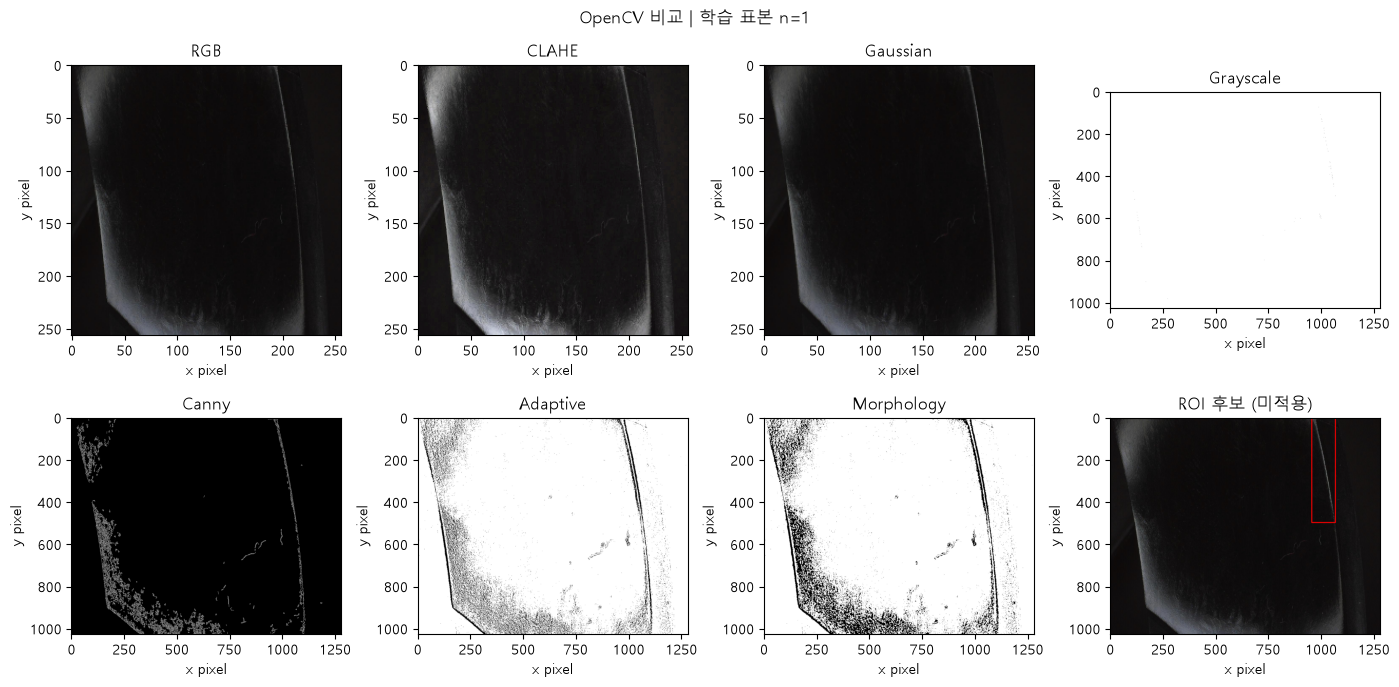

In [13]:
sample=read_rgb(train.iloc[0].path)
gray=cv2.cvtColor(sample,cv2.COLOR_RGB2GRAY)
canny=cv2.Canny(gray,60,150)
adaptive=cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                              cv2.THRESH_BINARY,31,5)
morph=cv2.morphologyEx(adaptive,cv2.MORPH_OPEN,np.ones((3,3),np.uint8))
contours,_=cv2.findContours(canny,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
roi=sample.copy()
if contours:
    x,y,w,h=cv2.boundingRect(max(contours,key=cv2.contourArea))
    cv2.rectangle(roi,(x,y),(x+w,y+h),(255,0,0),3)
views=[("RGB",preprocess(sample)),("CLAHE",preprocess(sample,"clahe")),
       ("Gaussian",preprocess(sample,"denoise")),("Grayscale",gray),
       ("Canny",canny),("Adaptive",adaptive),("Morphology",morph),("ROI 후보 (미적용)",roi)]
fig,axes=plt.subplots(2,4,figsize=(14,7))
for ax,(title,img) in zip(axes.flat,views):
    ax.imshow(img,cmap="gray",vmin=0,vmax=1) if img.ndim==2 else ax.imshow(img)
    ax.set_title(title);ax.set(xlabel="x pixel",ylabel="y pixel")
fig.suptitle("OpenCV 비교 | 학습 표본 n=1")
save_figure("opencv_comparison")

## PART 03. CNN 개선 실험과 검증 기반 선택
BatchNormalization은 중간 특징의 분포를 조절한다. Dropout은 과적합을 줄인다.
증강은 학습 중에만 적용하고, 적은 클래스에 가중치를 더 준다.
세 전처리의 개선 CNN과 기준 CNN 중 **검증 Macro F1**이 가장 높은 모델을 선택한다.
동점이면 더 단순한 기준 CNN을 유지한다. 최종 평가 점수로 선택하지 않는다.

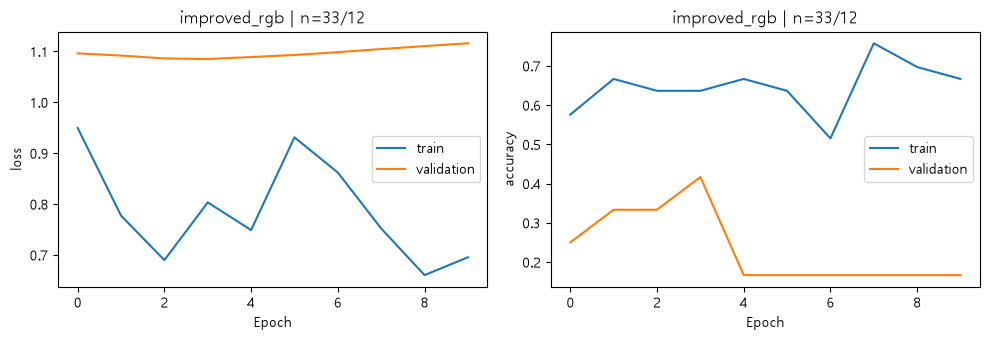

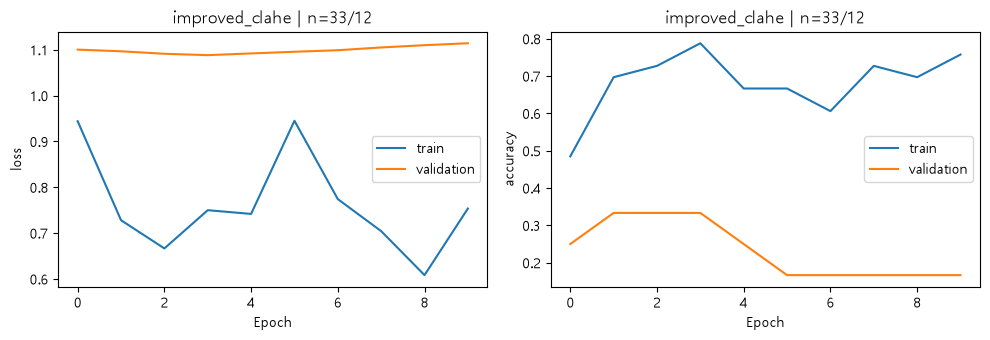

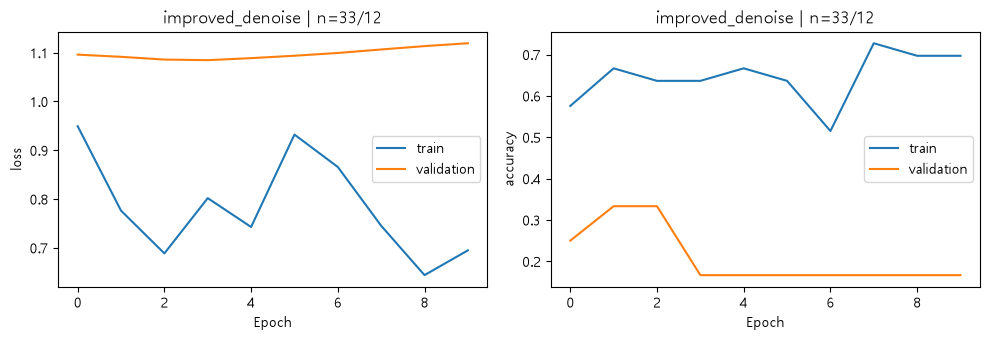

,model,preprocessing,validation_macro_f1,validation_accuracy,train_seconds,parameters
0,baseline_rgb,rgb,0.596825,0.833333,39.990360,101699
1,improved_rgb,rgb,0.454545,0.416667,25.936585,111843
2,improved_clahe,clahe,0.324074,0.333333,26.477422,111843
3,improved_denoise,denoise,0.095238,0.166667,36.638808,111843


검증으로 채택한 모델: baseline_rgb | 전처리: rgb


In [14]:
baseline, baseline_metadata = train_cnn("ring_cnn_baseline")
candidates=[dict(name="baseline_rgb",method="rgb",model=baseline,metadata=baseline_metadata)]
if TRAIN_IMPROVED_CNN:
    for method in ["rgb","clahe","denoise"]:
        model,metadata=train_cnn("ring_cnn_improved_"+method,method,True)
        candidates.append(dict(name="improved_"+method,method=method,model=model,metadata=metadata))
        plot_history(metadata,"improved_"+method)
validation_rows=[]
for c in candidates:
    result,prob=evaluate_types(c["model"],valid,c["method"],c["name"]+"_validation")
    c["validation_metrics"]=result
    validation_rows.append(dict(model=c["name"],preprocessing=c["method"],
        validation_macro_f1=result["macro_f1"],validation_accuracy=result["accuracy"],
        train_seconds=c["metadata"]["train_seconds"],parameters=result["parameters"]))
validation_table=pd.DataFrame(validation_rows)
display(validation_table)
validation_table.to_csv(OUT / "metrics/cnn_validation_comparison.csv",index=False)
chosen=max(candidates,key=lambda c:c["validation_metrics"]["macro_f1"])
final_model=chosen["model"]
FINAL_METHOD=chosen["method"]
MODEL_VERSION=f"ring-{RUN_MODE}-{DATA_SIGNATURE[:8]}-{chosen['name']}-v1"
final_model.save(MODELS / "ring_cnn_final.keras")
print("검증으로 채택한 모델:",chosen["name"],"| 전처리:",FINAL_METHOD)

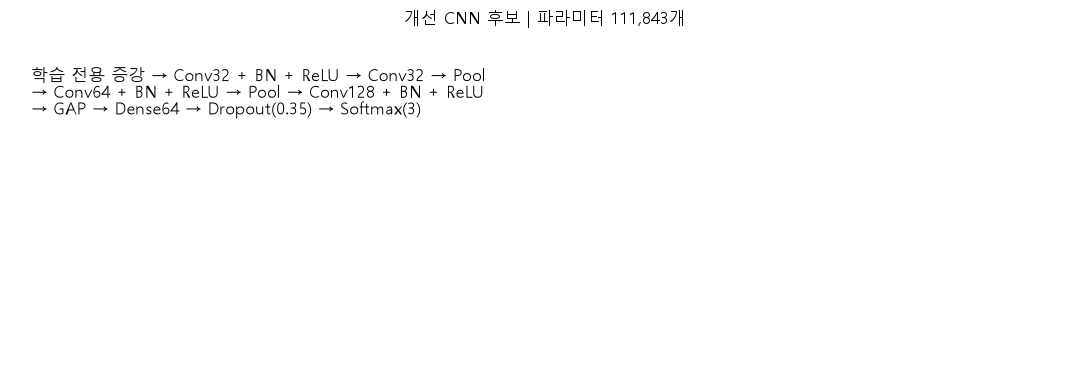

In [15]:
# 구조 표는 외부 Graphviz 설치 없이도 저장된다.
improved=next((c["model"] for c in candidates if c["name"]=="improved_rgb"),None)
if improved is not None:
    summary=[]
    improved.summary(print_fn=summary.append)
    (OUT / "metrics/improved_architecture.txt").write_text("\n".join(summary),encoding="utf-8")
    fig,ax=plt.subplots(figsize=(11,4))
    ax.axis("off")
    ax.text(0.02,0.9,"학습 전용 증강 → Conv32 + BN + ReLU → Conv32 → Pool\n"
            "→ Conv64 + BN + ReLU → Pool → Conv128 + BN + ReLU\n"
            "→ GAP → Dense64 → Dropout(0.35) → Softmax(3)",va="top",fontsize=12)
    ax.set_title(f"개선 CNN 후보 | 파라미터 {improved.count_params():,}개")
    save_figure("improved_architecture")

## PART 04. U-Net: 유형 분류에서 픽셀 위치 예측으로
CNN Encoder로 특징을 줄이고 Decoder로 위치를 복원한다.
Skip Connection으로 작은 결함의 위치 정보를 전달한다.
COCO polygon을 결함=1 / 나머지=0으로 합친다. 이 마스크는 **픽셀 정답**이며 정상 부품 라벨이 아니다.
원본 bbox에서 보완한 polygon의 품질 한계와 256×256 축소 손실이 남는다.

In [16]:
def polygon_mask(row):
    mask=np.zeros((int(row.height),int(row.width)),dtype=np.uint8)
    for a in annotations_by_key[row.image_id]:
        segments=a.get("segmentation",[])
        if not isinstance(segments,list):
            raise ValueError("이 노트북은 polygon만 지원하며 RLE는 별도 디코딩이 필요합니다.")
        for polygon in segments:
            points=np.asarray(polygon,dtype=np.float32).reshape(-1,2)
            if len(points)<3 or not np.isfinite(points).all():
                raise ValueError("유효하지 않은 polygon")
            cv2.fillPoly(mask,[np.rint(points).astype(np.int32)],1)
    return mask
def load_masks(frame):
    result=[]
    vanished=[]
    for _,row in frame.iterrows():
        original=polygon_mask(row)
        small=cv2.resize(original,(IMAGE_SIZE,IMAGE_SIZE),interpolation=cv2.INTER_NEAREST)
        if original.any() and not small.any():
            vanished.append(row.image_id)
        result.append(small[...,None])
    return np.asarray(result,dtype="float32"),vanished

MASKS_SUPPORTED=bool(annotations.has_polygon.all())
segmentation_metrics=None
segmentation_config=None
unet_model=None
if MASKS_SUPPORTED and TRAIN_UNET:
    M_train,lost_train=load_masks(train)
    M_valid,lost_valid=load_masks(valid)
    mask_audit=dict(polygon_supported=True,train_vanished=lost_train,validation_vanished=lost_valid,
        positive_pixel_fraction=float(M_train.mean()),resize="nearest",
        note="원본 polygon union. 배경 픽셀은 정상 부품 정답이 아님.")
    save_json(OUT / "metrics/mask_audit.json",mask_audit)
    if lost_train or lost_valid:
        print("축소 후 사라진 마스크:",lost_train,lost_valid)
        MASKS_SUPPORTED=False
    else:
        print("학습 결함 픽셀 비율:",float(M_train.mean()))
else:
    print("U-Net 생략: polygon 부적합 또는 TRAIN_UNET=False")

학습 결함 픽셀 비율: 0.00708146532997489


In [17]:
# 이미지와 마스크를 함께 뒤집어 위치가 어긋나지 않도록 한다.
class PairedBatches(keras.utils.Sequence):
    def __init__(self,x,m,batch_size=8):
        self.x,self.m,self.batch_size=x,m,batch_size
        self.epoch=0
    def __len__(self):
        return int(np.ceil(len(self.x)/self.batch_size))
    def __getitem__(self,index):
        rng=np.random.default_rng(SEED+self.epoch*1000+index)
        order=np.random.default_rng(SEED+self.epoch).permutation(len(self.x))
        ids=order[index*self.batch_size:(index+1)*self.batch_size]
        x,m=self.x[ids].copy(),self.m[ids].copy()
        for j in range(len(x)):
            if rng.random()<0.5: x[j],m[j]=x[j,::-1],m[j,::-1]
            if rng.random()<0.5: x[j],m[j]=x[j,:,::-1],m[j,:,::-1]
        return x,m
    def on_epoch_end(self):
        self.epoch+=1

def dice_coefficient(y_true,y_prob):
    axes=(1,2,3)
    intersection=tf.reduce_sum(y_true*y_prob,axis=axes)
    union=tf.reduce_sum(y_true+y_prob,axis=axes)
    return tf.reduce_mean((2*intersection+1e-6)/(union+1e-6))
def bce_dice_loss(y_true,y_prob):
    bce=tf.reduce_mean(keras.losses.binary_crossentropy(y_true,y_prob))
    return bce+1.0-dice_coefficient(y_true,y_prob)
def build_unet():
    inputs=keras.Input((IMAGE_SIZE,IMAGE_SIZE,3))
    def block(x,filters):
        x=layers.Conv2D(filters,3,padding="same",activation="relu")(x)
        return layers.Conv2D(filters,3,padding="same",activation="relu")(x)
    skips=[]
    x=inputs
    for filters in [8,16,32]:
        x=block(x,filters);skips.append(x);x=layers.MaxPooling2D()(x)
    x=block(x,64)
    for filters,skip in zip([32,16,8],reversed(skips)):
        x=layers.UpSampling2D(interpolation="bilinear")(x)
        x=layers.Concatenate()([x,skip])
        x=block(x,filters)
    return keras.Model(inputs,layers.Conv2D(1,1,activation="sigmoid")(x),name="ring_unet")

In [18]:
# 학습 손실을 BCE / BCE+Dice로 비교한다. 검증 Dice로 선택한다.
def segmentation_scores(truth,prob,threshold):
    actual=truth>0.5
    predicted=prob>=threshold
    tp=int(np.logical_and(actual,predicted).sum())
    fp=int(np.logical_and(~actual,predicted).sum())
    fn=int(np.logical_and(actual,~predicted).sum())
    axes=(1,2,3)
    intersections=np.logical_and(actual,predicted).sum(axis=axes)
    totals=actual.sum(axis=axes)+predicted.sum(axis=axes)
    dices=np.divide(2*intersections,totals,out=np.ones(len(totals),dtype=float),where=totals>0)
    unions=np.logical_or(actual,predicted).sum(axis=axes)
    ious=np.divide(intersections,unions,out=np.ones(len(unions),dtype=float),where=unions>0)
    return dict(mean_dice=float(dices.mean()),mean_iou=float(ious.mean()),
        pixel_precision=tp/(tp+fp) if tp+fp else 0.0,
        pixel_recall=tp/(tp+fn) if tp+fn else 0.0,
        pixel_tp=tp,pixel_fp=fp,pixel_fn=fn)

def train_unet(loss_name):
    path=MODELS / f"ring_unet_{loss_name}.keras"
    meta_path=path.with_suffix(".json")
    signature=dict(data=DATA_SIGNATURE,size=IMAGE_SIZE,epochs=UNET_EPOCHS,
                   seed=SEED,mode=RUN_MODE,loss=loss_name,version=1)
    if USE_SAVED_MODELS and path.exists() and meta_path.exists():
        meta=json.loads(meta_path.read_text(encoding="utf-8"))
        if meta["signature"]==signature:
            return keras.models.load_model(path,compile=False),meta
    tf.keras.utils.set_random_seed(SEED)
    model=build_unet()
    model.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss="binary_crossentropy" if loss_name=="bce" else bce_dice_loss,
                  metrics=[dice_coefficient])
    start=time.perf_counter()
    hist=model.fit(PairedBatches(X_train,M_train),validation_data=(X_valid,M_valid),
        epochs=UNET_EPOCHS,verbose=2,callbacks=[
            keras.callbacks.EarlyStopping(monitor="val_dice_coefficient",mode="max",
                                           patience=5,restore_best_weights=True),
            keras.callbacks.ModelCheckpoint(str(path),monitor="val_dice_coefficient",
                                            mode="max",save_best_only=True)])
    meta=dict(signature=signature,history=hist.history,train_seconds=time.perf_counter()-start)
    save_json(meta_path,meta)
    return keras.models.load_model(path,compile=False),meta

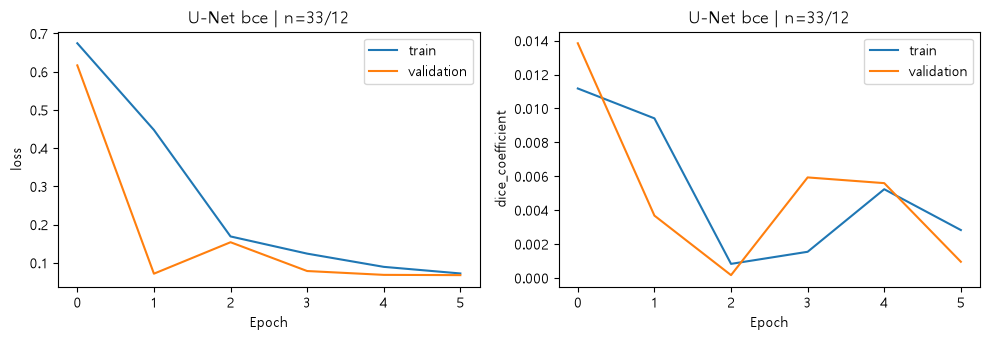

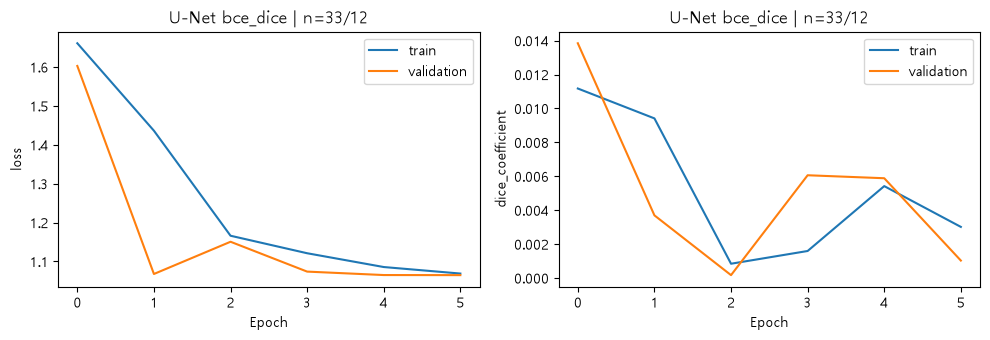

U-Net 시연 적용: False
검증으로 선택: bce 픽셀 임계값: 0.05


In [19]:
unet_candidates=[]
if MASKS_SUPPORTED and TRAIN_UNET:
    for loss_name in ["bce","bce_dice"]:
        model,metadata=train_unet(loss_name)
        prob=model.predict(X_valid,batch_size=8,verbose=0)
        # 검증 데이터만 사용하여 픽셀 임계값을 선택한다.
        grid=np.linspace(0.05,0.95,19)
        rows=[dict(threshold=float(t),**segmentation_scores(M_valid,prob,t)) for t in grid]
        curve=pd.DataFrame(rows)
        curve.to_csv(OUT / "metrics" / f"unet_{loss_name}_thresholds.csv",index=False)
        best=max(rows,key=lambda r:r["mean_dice"])
        unet_candidates.append(dict(loss=loss_name,model=model,metadata=metadata,**best))
        fig,axes=plt.subplots(1,2,figsize=(10,3.5))
        for ax,key in zip(axes,["loss","dice_coefficient"]):
            ax.plot(metadata["history"][key],label="train")
            ax.plot(metadata["history"]["val_"+key],label="validation")
            ax.set(xlabel="Epoch",ylabel=key,title=f"U-Net {loss_name} | n={len(train)}/{len(valid)}")
            ax.legend()
        save_figure("unet_"+loss_name+"_history")
    best_unet=max(unet_candidates,key=lambda r:r["mean_dice"])
    unet_model=best_unet["model"]
    PIXEL_THRESHOLD=best_unet["threshold"]
    unet_model.save(MODELS / "ring_unet.keras")
    segmentation_config=dict(model_path=(MODELS/"ring_unet.keras").relative_to(PROJECT_ROOT).as_posix(),
        preprocessing="rgb",threshold=PIXEL_THRESHOLD,loss=best_unet["loss"],
        label="공식 polygon에 대한 결함 위치 추정",data_signature=DATA_SIGNATURE)
    trivial=segmentation_scores(M_valid,np.ones_like(M_valid),0.5)["mean_dice"]
    segmentation_config.update(
        enabled_for_inference=bool(best_unet["mean_dice"]>=MIN_LOCALIZATION_VALID_DICE
                                  and best_unet["mean_dice"]>trivial+0.02),
        validation_dice=best_unet["mean_dice"],all_foreground_validation_dice=trivial,
        acceptance_rule="validation Dice >= 0.10 and > all-foreground Dice + 0.02")
    print("U-Net 시연 적용:",segmentation_config["enabled_for_inference"])
    save_json(OUT / "metrics/unet_selection.json",{
        "selected":segmentation_config,"candidates":[
        {k:c[k] for k in ["loss","threshold","mean_dice","mean_iou"]} for c in unet_candidates]})
    print("검증으로 선택:",best_unet["loss"],"픽셀 임계값:",PIXEL_THRESHOLD)

## PART 05. Autoencoder
정상 표본만 복원하도록 학습해야 하므로 이번 데이터에서는 실행하지 않는다.
정답 없는 inference를 정상으로 간주해 학습하지 않는다.

In [20]:
if TRAIN_AUTOENCODER:
    print("요청한 Autoencoder를 생략합니다:",LABEL_REASON)
else:
    print("Autoencoder 비활성화 — 검증된 정상 데이터 없음")

Autoencoder 비활성화 — 검증된 정상 데이터 없음


## PART 06. 선택을 고정한 뒤 최종 평가
아래에서 처음으로 최종 모델을 홀드아웃에 평가한다.
기준 CNN·개선 CNN의 유형 분류와 U-Net의 픽셀 분할은 별도의 표로 저장한다.

,model,preprocessing,accuracy,macro_f1,mean_inference_ms,parameters,train_seconds,selected
0,baseline_rgb,rgb,0.809524,0.567766,9.000429,101699,39.990360,True
1,improved_rgb,rgb,0.095238,0.059259,11.194605,111843,25.936585,False
2,improved_clahe,clahe,0.380952,0.366522,12.959902,111843,26.477422,False
3,improved_denoise,denoise,0.095238,0.057971,13.313898,111843,36.638808,False


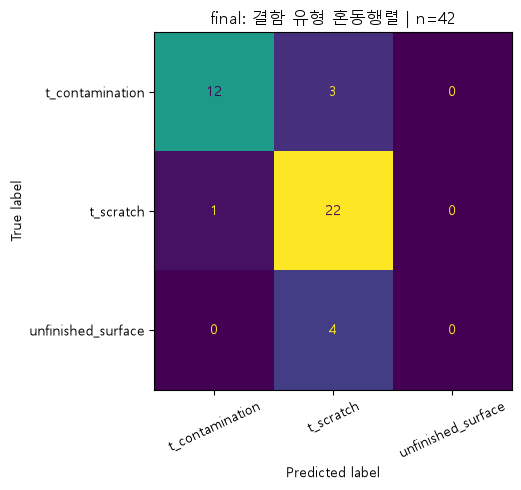

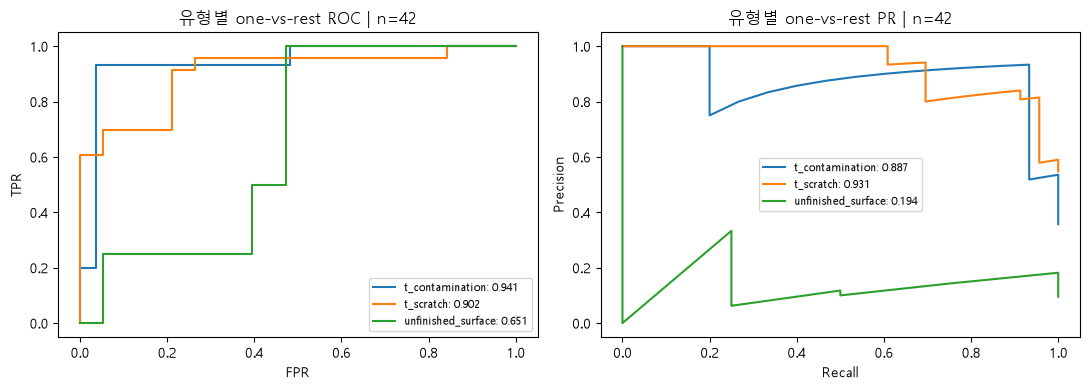

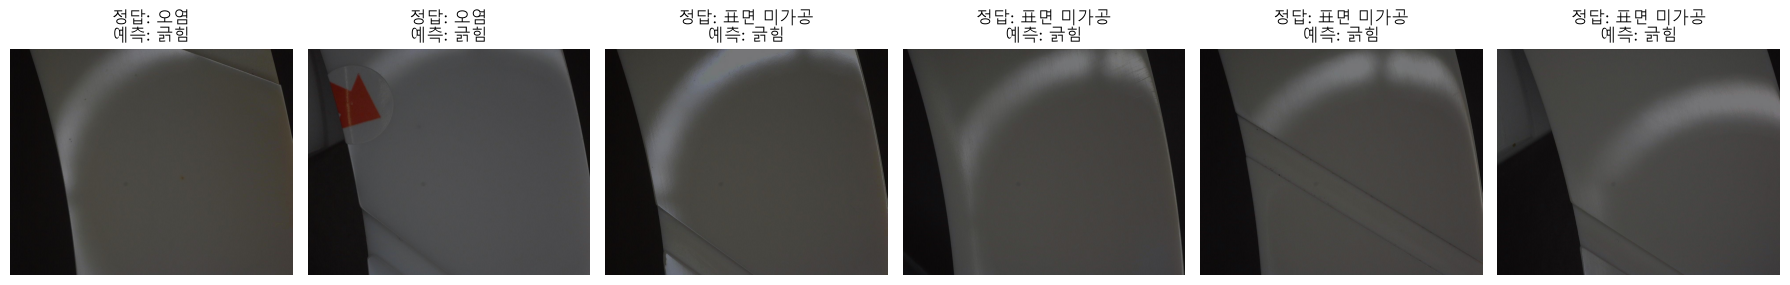

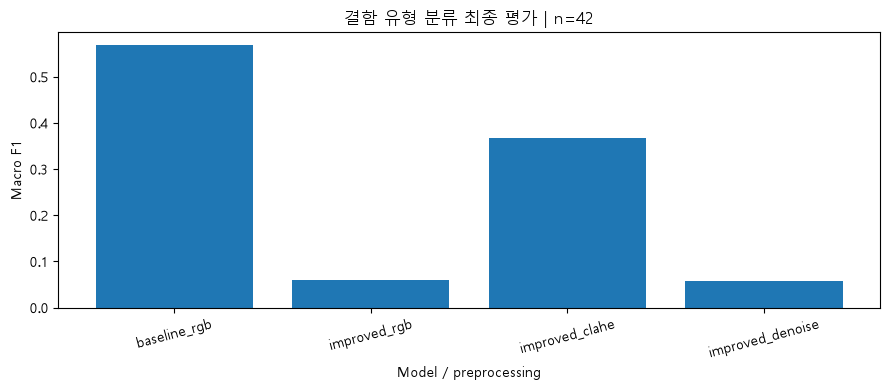

In [21]:
comparison=[]
for c in candidates:
    result,prob=evaluate_types(c["model"],holdout,c["method"],c["name"]+"_holdout")
    comparison.append(dict(model=c["name"],preprocessing=c["method"],
        accuracy=result["accuracy"],macro_f1=result["macro_f1"],
        mean_inference_ms=result["mean_inference_ms"],parameters=result["parameters"],
        train_seconds=c["metadata"]["train_seconds"]))
    if c["name"]==chosen["name"]:
        final_metrics,final_probabilities=result,prob
comparison=pd.DataFrame(comparison)
comparison["selected"]=comparison.model.eq(chosen["name"])
display(comparison)
comparison.to_csv(OUT / "metrics/cnn_holdout_comparison.csv",index=False)
plot_classification(holdout,final_probabilities,"final")
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(comparison.model,comparison.macro_f1)
ax.set(xlabel="Model / preprocessing",ylabel="Macro F1",
       title=f"결함 유형 분류 최종 평가 | n={len(holdout)}")
ax.tick_params(axis="x",rotation=15)
save_figure("cnn_comparison")

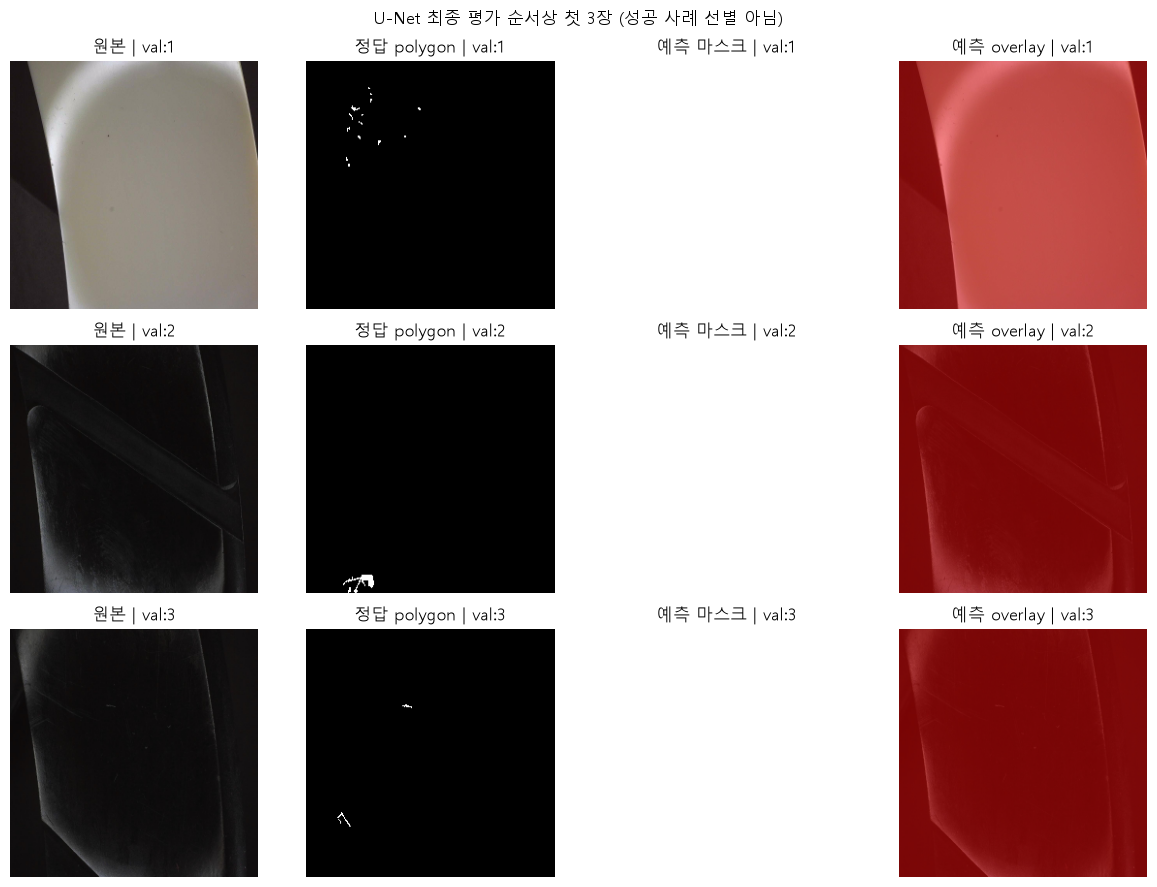

,mean_dice,mean_iou,pixel_precision,pixel_recall,pixel_tp,pixel_fp,pixel_fn,task,run_mode,evaluation_images,pixel_threshold,selected_loss,vanished_holdout_masks
0,0.007537,0.003864,0.003864,1.0,10637,2741875,0,polygon_union_segmentation,full,42,0.05,bce,[]


In [22]:
if unet_model is not None:
    X_holdout,_=load_xy(holdout)
    M_holdout,lost_holdout=load_masks(holdout)
    mask_probabilities=unet_model.predict(X_holdout,batch_size=8,verbose=0)
    segmentation_metrics=segmentation_scores(M_holdout,mask_probabilities,PIXEL_THRESHOLD)
    segmentation_metrics.update(task="polygon_union_segmentation",run_mode=RUN_MODE,
        evaluation_images=len(holdout),pixel_threshold=PIXEL_THRESHOLD,
        selected_loss=best_unet["loss"],vanished_holdout_masks=lost_holdout)
    save_json(OUT / "metrics/ring_unet_metrics.json",segmentation_metrics)
    # 첫 표본 3개를 고정해 결과가 좋은 이미지만 고르지 않는다.
    fig,axes=plt.subplots(3,4,figsize=(12,9))
    for j in range(3):
        image=X_holdout[j]
        pred=mask_probabilities[j,:,:,0]>=PIXEL_THRESHOLD
        overlay=image.copy()
        overlay[pred]=0.55*overlay[pred]+0.45*np.array([1.,0.,0.])
        for ax,img,title in zip(axes[j],
            [image,M_holdout[j,:,:,0],pred,overlay],["원본","정답 polygon","예측 마스크","예측 overlay"]):
            ax.imshow(img,cmap="gray",vmin=0,vmax=1) if img.ndim==2 else ax.imshow(img)
            ax.set_title(f"{title} | {holdout.iloc[j].image_id}");ax.axis("off")
    fig.suptitle("U-Net 최종 평가 순서상 첫 3장 (성공 사례 선별 아님)")
    save_figure("unet_holdout_overlay")
    display(pd.DataFrame([segmentation_metrics]))
else:
    print("U-Net 정량 결과 없음. 원본 bbox는 EDA에만 표시하며 예측처럼 제시하지 않음.")

## PART 07. 임계값과 판정의 범위
정상/불량 Recall 95% 목표는 정상·불량 정답이 함께 있는 검증 세트가 필요하다.
현재는 이진 임계값을 정하지 않는다. 유형별 임계값 곡선은 유형을 놓치는 정도만 보여 준다.
유형 신뢰도 기준도 검증 자료에서만 계산하며 제조 검사 판정은 모두 REVIEW다.

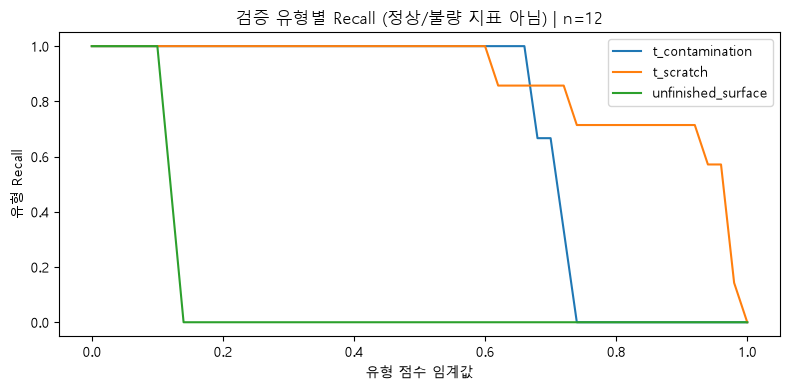

이진 검사 임계값: N/A | 유형 신뢰도 보조 기준: 0.7008383274078369


In [23]:
_,validation_probabilities=evaluate_types(final_model,valid,FINAL_METHOD,"selected_validation")
correct=validation_probabilities.argmax(1)==valid.label.to_numpy()
TYPE_CONFIDENCE_THRESHOLD=(float(np.quantile(validation_probabilities.max(1)[correct],0.2))
                           if correct.any() else None)
threshold_rows=[]
fig,ax=plt.subplots(figsize=(8,4))
for i,name in enumerate(CLASS_NAMES):
    truth=valid.label.to_numpy()==i
    recalls=[]
    for t in np.linspace(0,1,51):
        recall=float((validation_probabilities[truth,i]>=t).mean()) if truth.any() else None
        threshold_rows.append(dict(type=name,threshold=float(t),type_recall=recall,split="validation"))
        recalls.append(recall)
    ax.plot(np.linspace(0,1,51),recalls,label=name)
ax.set(xlabel="유형 점수 임계값",ylabel="유형 Recall",
       title=f"검증 유형별 Recall (정상/불량 지표 아님) | n={len(valid)}")
ax.legend()
save_figure("type_threshold_curves")
pd.DataFrame(threshold_rows).to_csv(OUT / "metrics/type_threshold_curves.csv",index=False)
print("이진 검사 임계값: N/A | 유형 신뢰도 보조 기준:",TYPE_CONFIDENCE_THRESHOLD)

In [24]:
# 정상/불량 정답을 나중에 확보했을 때만 사용할 함수
def select_binary_threshold(y_true,defect_scores,target_recall=TARGET_RECALL):
    y=np.asarray(y_true)
    scores=np.asarray(defect_scores,dtype=float)
    if set(np.unique(y))!={0,1}:
        raise ValueError("검증된 정상(0)과 불량(1)이 모두 필요합니다.")
    if len(y)!=len(scores) or not np.isfinite(scores).all() or ((scores<0)|(scores>1)).any():
        raise ValueError("정답과 0~1 불량 점수가 필요합니다.")
    if not 0<target_recall<=1:
        raise ValueError("목표 Recall은 0 초과 1 이하여야 합니다.")
    results=[]
    for threshold in np.unique(np.r_[0.,scores,1.]):
        pred=scores>=threshold
        tp=int(((y==1)&pred).sum());fp=int(((y==0)&pred).sum())
        fn=int(((y==1)&~pred).sum());tn=int(((y==0)&~pred).sum())
        recall=tp/(tp+fn)
        if recall>=target_recall:
            results.append(dict(threshold=float(threshold),recall=recall,
                                false_positive_rate=fp/(fp+tn)))
    return min(results,key=lambda r:(r["false_positive_rate"],-r["threshold"]))
print("위 함수는 현재 유형 Softmax 점수에 적용하지 않습니다.")

위 함수는 현재 유형 Softmax 점수에 적용하지 않습니다.


## PART 08. 사전 검사 효과와 가정 시뮬레이션
이진 검사 모델이 없어 실제 TP/FP/TN/FN, 잔존 불량과 감소율은 N/A다.
아래는 사용자가 가정한 불량률·Recall·정상 오검출률로 계산하는 시나리오 도구다.
이번 모델의 실측 성능이 아니다. REVIEW는 자동 출하 승인에 사용하지 않는다.

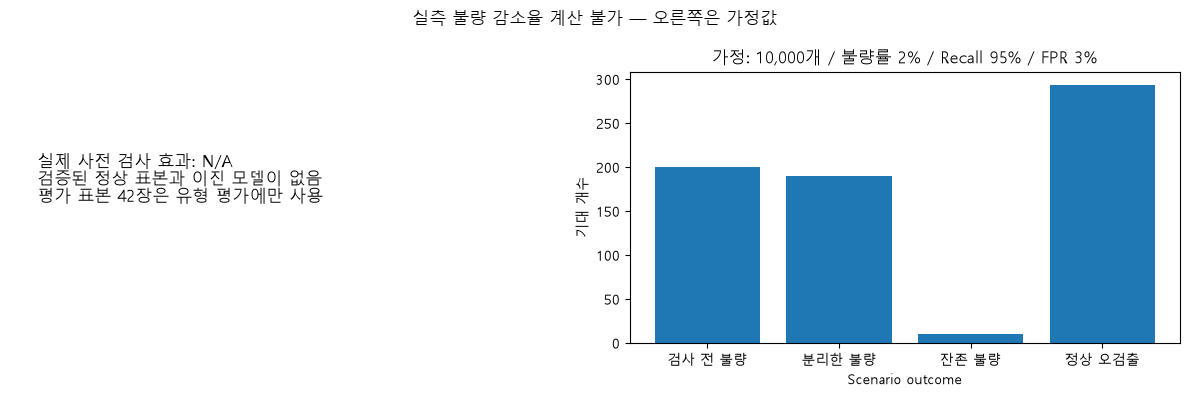

In [25]:
def simulate_preinspection(total,prevalence,assumed_recall,assumed_fpr):
    if total<=0 or int(total)!=total:
        raise ValueError("투입량은 양의 정수여야 합니다.")
    if any(not 0<=v<=1 for v in [prevalence,assumed_recall,assumed_fpr]):
        raise ValueError("비율은 0~1 범위여야 합니다.")
    defective=total*prevalence
    return dict(kind="hypothetical_scenario_not_measured",total=int(total),
        assumed_prevalence=prevalence,assumed_recall=assumed_recall,assumed_fpr=assumed_fpr,
        defective_before=defective,separated_defective=defective*assumed_recall,
        remaining_defective=defective*(1-assumed_recall),
        false_rejected_normal=total*(1-prevalence)*assumed_fpr,
        inflow_reduction_pct=100*assumed_recall if defective>0 else None)
# 아래 수치는 설명을 위한 가정이며 모델 성능이 아니다.
scenario=simulate_preinspection(10000,0.02,0.95,0.03)
save_json(OUT / "metrics/hypothetical_scenario.json",scenario)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].axis("off")
axes[0].text(0.05,0.7,"실제 사전 검사 효과: N/A\n검증된 정상 표본과 이진 모델이 없음\n"
    f"평가 표본 {len(holdout)}장은 유형 평가에만 사용",fontsize=12,va="top")
keys=["defective_before","separated_defective","remaining_defective","false_rejected_normal"]
axes[1].bar(["검사 전 불량","분리한 불량","잔존 불량","정상 오검출"],[scenario[k] for k in keys])
axes[1].set(xlabel="Scenario outcome",ylabel="기대 개수",
    title="가정: 10,000개 / 불량률 2% / Recall 95% / FPR 3%")
fig.suptitle("실측 불량 감소율 계산 불가 — 오른쪽은 가정값")
save_figure("preinspection_effect_and_scenario")

## 팀 통합 CSV / JSON
정상/불량 의미의 열은 null이다. 실제 유형 정답은 true_defect_type에 저장한다.
inference는 평가 CSV에서 제외한다. REVIEW는 수동 검토 대상으로 보류하며 NG 분리 실적으로 계산하지 않는다.

In [26]:
predicted_types=final_probabilities.argmax(1)
integration=pd.DataFrame({
    "image_id":holdout.image_id,"part_type":"Ring","split":"holdout_from_official_val",
    "y_true":None,"defect_score":None,"threshold":None,"y_pred":None,"decision":"REVIEW",
    "model_version":MODEL_VERSION,"binary_supported":False,
    "true_defect_type":holdout.label.map(dict(enumerate(CLASS_NAMES))),
    "predicted_defect_type":[CLASS_NAMES[i] for i in predicted_types],
    "type_confidence":final_probabilities.max(1),
    "type_confidence_threshold":TYPE_CONFIDENCE_THRESHOLD})
for i,name in enumerate(CLASS_NAMES):
    integration["prob_"+name]=final_probabilities[:,i]
integration.to_csv(OUT / "integration/ring_predictions.csv",index=False)
binary_nulls={k:None for k in ["threshold","TP","FP","TN","FN","Accuracy","Precision",
    "Recall","F1","ROC_AUC","Average_Precision","inflow_reduction_pct","normal_false_positive_rate"]}
ring_metrics=dict(dataset="Ring",task="defect_type_multiclass",run_mode=RUN_MODE,
    binary_supported=False,binary_unavailable_reason=LABEL_REASON,
    train_images=len(train),validation_images=len(valid),evaluation_images=len(holdout),
    model_version=MODEL_VERSION,selected_model=chosen["name"],
    multiclass=final_metrics,segmentation=segmentation_metrics,
    data_signature=DATA_SIGNATURE,review_policy="전부 수동 검토. 자동 OK/NG 또는 NG 분리 실적으로 사용하지 않음.",
    **binary_nulls)
save_json(OUT / "integration/ring_metrics.json",ring_metrics)
config=dict(dataset="Ring",model_name=chosen["name"],model_version=MODEL_VERSION,
    model_path=(MODELS/"ring_cnn_final.keras").relative_to(PROJECT_ROOT).as_posix(),
    input_size=[IMAGE_SIZE,IMAGE_SIZE],channel_order="RGB",
    normalization="float32 / 255.0",preprocessing=FINAL_METHOD,
    resize="cv2.INTER_AREA; full frame resized to square",
    clahe=dict(color_space="LAB",clipLimit=2.0,tileGridSize=[8,8]),
    denoise=dict(method="GaussianBlur",kernel=[3,3],sigma=0),
    classes=[dict(index=i,name=name,korean=CLASS_KO[name]) for i,name in enumerate(CLASS_NAMES)],
    binary_supported=False,defect_score_meaning=None,threshold=None,
    type_confidence_threshold=TYPE_CONFIDENCE_THRESHOLD,
    review_policy=ring_metrics["review_policy"],segmentation=segmentation_config,
    source_url=SOURCE_URL,data_signature=DATA_SIGNATURE,run_mode=RUN_MODE,
    limitations=[LABEL_REASON,"소량 데이터","근접 중복 미검증",
                 "256 축소에 따른 미세 결함 손실","polygon은 원본 bbox 보완 라벨",
                 "Softmax 점수는 확률 보정되지 않음"],
    split_policy="공식 train 내부 75:25 분리. 공식 val을 최종 홀드아웃으로 재지정")
save_json(OUT / "integration/ring_model_config.json",config)
if unet_model is not None:
    for j,row in holdout.iterrows():
        mask=(mask_probabilities[j,:,:,0]>=PIXEL_THRESHOLD).astype("uint8")*255
        cv2.imencode(".png",mask)[1].tofile(str(OUT / "predictions" / f"holdout_{row.image_id.replace(':','_')}_mask.png"))
print("통합 파일 3개 저장 완료:",OUT / "integration")

통합 파일 3개 저장 완료: C:\Users\kdt66\Desktop\FoldedVision_AI\outputs\integration


## PART 09. 저장 모델로 추론하기
config와 저장된 Keras 모델을 로드한다. 이 추론 셀은 원본 데이터셋이 필요하지 않다.
RGB uint8 배열, PIL 이미지 또는 파일 경로를 받는다.
제조 판정은 REVIEW, defect_score와 threshold는 null이다.
결함 유형과 U-Net 마스크는 실제 모델 출력이다.

In [27]:
_predictor=None
def load_ring_predictor():
    path=OUT / "integration/ring_model_config.json"
    if not path.is_file():
        raise FileNotFoundError("통합 설정 파일이 없습니다. 결과 저장을 먼저 실행하세요.")
    cfg=json.loads(path.read_text(encoding="utf-8"))
    classifier_path=PROJECT_ROOT / cfg["model_path"]
    if not classifier_path.is_file():
        raise FileNotFoundError(f"저장 모델 없음: {classifier_path}")
    classifier=keras.models.load_model(classifier_path,compile=False)
    segmenter=None
    if cfg.get("segmentation") and cfg["segmentation"].get("enabled_for_inference",False):
        mask_path=PROJECT_ROOT / cfg["segmentation"]["model_path"]
        if not mask_path.is_file():
            raise FileNotFoundError(f"U-Net 모델 없음: {mask_path}")
        segmenter=keras.models.load_model(mask_path,compile=False)
    if classifier.output_shape[-1]!=len(cfg["classes"]):
        raise ValueError("모델 출력과 클래스 설정이 다릅니다.")
    return cfg,classifier,segmenter

def gradcam_attention(classifier,x,class_index):
    # 분류 근거를 보는 열지도이며 결함 마스크가 아니다.
    conv=next(layer for layer in reversed(classifier.layers)
              if isinstance(layer,layers.Conv2D))
    gradient_model=keras.Model(classifier.inputs,[conv.output,classifier.output])
    with tf.GradientTape() as tape:
        features,scores=gradient_model(x,training=False)
        objective=scores[:,class_index]
    gradients=tape.gradient(objective,features)
    weights=tf.reduce_mean(gradients,axis=(1,2),keepdims=True)
    heat=tf.nn.relu(tf.reduce_sum(weights*features,axis=-1))[0].numpy()
    return heat/(float(heat.max())+1e-8)

def predict_ring(image):
    global _predictor
    if _predictor is None:
        _predictor=load_ring_predictor()
    cfg,classifier,segmenter=_predictor
    rgb=read_rgb(image) if isinstance(image,(str,Path)) else np.asarray(image)
    if rgb.ndim!=3 or rgb.shape[2]!=3 or rgb.dtype!=np.uint8:
        raise ValueError("RGB uint8 3채널 이미지를 입력하세요.")
    start=time.perf_counter()
    size=cfg["input_size"][0]
    x=preprocess(rgb,cfg["preprocessing"],size=size)[None]
    scores=classifier(x,training=False).numpy()[0]
    label=int(scores.argmax())
    saved_mask=None
    if segmenter is not None:
        probabilities=segmenter(preprocess(rgb,"rgb",size=size)[None],training=False).numpy()[0,:,:,0]
        mask=(probabilities>=cfg["segmentation"]["threshold"]).astype("uint8")*255
        mask=cv2.resize(mask,(rgb.shape[1],rgb.shape[0]),interpolation=cv2.INTER_NEAREST)
        path=OUT / "predictions" / f"ring_{time.time_ns()}_mask.png"
        cv2.imencode(".png",mask)[1].tofile(str(path))
        saved_mask=str(path)
    attention=gradcam_attention(classifier,x,label)
    attention=cv2.resize(attention,(rgb.shape[1],rgb.shape[0]),interpolation=cv2.INTER_LINEAR)
    heatmap_path=OUT / "predictions" / f"ring_{time.time_ns()}_attention.png"
    cv2.imencode(".png",(attention*255).astype("uint8"))[1].tofile(str(heatmap_path))
    confidence=float(scores.max())
    return dict(part_type="Ring",status="REVIEW",defect_score=None,threshold=None,
        model_version=cfg["model_version"],mask_path=saved_mask,heatmap_path=str(heatmap_path),
        localization_method="unet_mask" if saved_mask else "gradcam_attention_not_defect_mask",
        inference_ms=(time.perf_counter()-start)*1000,
        defect_type=cfg["classes"][label]["name"],
        defect_type_korean=cfg["classes"][label]["korean"],type_confidence=confidence,
        class_probabilities={c["name"]:float(scores[i]) for i,c in enumerate(cfg["classes"])},
        type_low_confidence=(confidence<cfg["type_confidence_threshold"]
                            if cfg["type_confidence_threshold"] is not None else True),
        decision_reason="정상 데이터가 없어 정상/불량 판정은 지원하지 않습니다.")

In [28]:
sample_result=predict_ring(holdout.iloc[0].path)
display(sample_result)
save_json(OUT / "metrics/inference_smoke_result.json",sample_result)
assert sample_result["status"]=="REVIEW" and sample_result["defect_score"] is None

{'part_type': 'Ring',
 'status': 'REVIEW',
 'defect_score': None,
 'threshold': None,
 'model_version': 'ring-full-39c0eaa2-baseline_rgb-v1',
 'mask_path': None,
 'heatmap_path': 'C:\\Users\\kdt66\\Desktop\\FoldedVision_AI\\outputs\\predictions\\ring_1794986371965877900_attention.png',
 'localization_method': 'gradcam_attention_not_defect_mask',
 'inference_ms': 120.62930001411587,
 'defect_type': 't_contamination',
 'defect_type_korean': '오염',
 'type_confidence': 0.6452713012695312,
 'class_probabilities': {'t_contamination': 0.6452713012695312,
  't_scratch': 0.2256929576396942,
  'unfinished_surface': 0.12903572618961334},
 'type_low_confidence': True,
 'decision_reason': '정상 데이터가 없어 정상/불량 판정은 지원하지 않습니다.'}

In [29]:
os.environ.setdefault("GRADIO_ANALYTICS_ENABLED","False")
import gradio as gr
def inspect_ring_ui(image):
    if image is None:
        return "Ring 이미지를 입력하세요.",None,None
    result=predict_ring(image)
    overlay=np.asarray(image).copy()
    if result["mask_path"]:
        mask=cv2.imdecode(np.fromfile(result["mask_path"],dtype=np.uint8),cv2.IMREAD_GRAYSCALE)>0
        overlay[mask]=(0.55*overlay[mask]+0.45*np.array([255,0,0])).astype("uint8")
    elif result["heatmap_path"]:
        heat=cv2.imdecode(np.fromfile(result["heatmap_path"],dtype=np.uint8),cv2.IMREAD_GRAYSCALE)
        colors=cv2.cvtColor(cv2.applyColorMap(heat,cv2.COLORMAP_JET),cv2.COLOR_BGR2RGB)
        overlay=(0.65*overlay+0.35*colors).astype("uint8")
    text=(f"판정: REVIEW (정상/불량 분류 미지원)\n"
          f"추정 결함 유형: {result['defect_type_korean']}\n"
          f"유형 점수: {result['type_confidence']:.3f} (불량 확률 아님)\n"
          f"모델: {result['model_version']}\n추론: {result['inference_ms']:.1f} ms")
    text += "\n위치 시각화: Grad-CAM은 분류 근거이며 결함 마스크가 아닙니다."
    return text,result,overlay
with gr.Blocks(title="FoldedVision Ring") as demo:
    gr.Markdown("# FoldedVision AI — Ring 결함 유형·위치 검사\n"
                "공개 Ring 이미지용 시연입니다. 정상/불량 판정은 지원하지 않습니다.")
    image_input=gr.Image(type="numpy",image_mode="RGB",label="Ring 이미지")
    run_button=gr.Button("검사")
    result_text=gr.Textbox(label="검사 결과",lines=5)
    result_json=gr.JSON(label="팀 통합 결과")
    image_output=gr.Image(label="위치 시각화: Grad-CAM 주목 영역 / 검증 통과 시 U-Net")
    run_button.click(inspect_ring_ui,inputs=image_input,outputs=[result_text,result_json,image_output],api_name="inspect_ring")
if LAUNCH_UI:
    demo.launch(server_name="127.0.0.1",share=False,inbrowser=False)
else:
    print("UI 구성 완료. 첫 설정 셀 LAUNCH_UI=True로 바꾸고 이 셀을 실행하세요.")

C:\Users\kdt66\Desktop\FoldedVision_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


UI 구성 완료. 첫 설정 셀 LAUNCH_UI=True로 바꾸고 이 셀을 실행하세요.


## 실제 실행 결과와 발표용 결론
보고서는 계산한 값으로 자동 작성한다. quick 결과와 full 결과를 구분한다.

In [30]:
baseline_row=comparison[comparison.model=="baseline_rgb"].iloc[0]
selected_row=comparison[comparison.model==chosen["name"]].iloc[0]
improved_rows=comparison[comparison.model.str.startswith("improved")]
improved_text="실행 안 함" if improved_rows.empty else improved_rows[["model","accuracy","macro_f1"]].to_string(index=False)
unet_text=("적용 안 함" if segmentation_metrics is None else
           f"Dice {segmentation_metrics['mean_dice']:.4f}, IoU {segmentation_metrics['mean_iou']:.4f}, "
           f"Pixel Recall {segmentation_metrics['pixel_recall']:.4f}")
report=f'''# Ring 개발 결과 ({RUN_MODE})
## 실제 데이터
전체 {len(images)}장 / 결함 정답 {len(labeled)}장 / 검증된 정상 0장 / 정답 미공개 {audit['unlabeled_images']}장.
결함 유형: {', '.join(CLASS_NAMES)}.
학습 {len(train)}장, 검증 {len(valid)}장, 최종 평가 {len(holdout)}장.
공식 val을 최종 평가로 재지정했다. inference는 정량 평가에서 제외했다.

## 실제 학습 결과
기준 CNN: 정확도 {baseline_row.accuracy:.4f}, Macro F1 {baseline_row.macro_f1:.4f}.
개선 CNN 후보들의 최종 평가:
{improved_text}

검증으로 선택한 최종 모델: {chosen['name']} ({FINAL_METHOD}).
선정 이유: 검증 Macro F1 최대, 동점이면 기준 CNN 유지.
최종 정확도 {selected_row.accuracy:.4f}, Macro F1 {selected_row.macro_f1:.4f}.
기준 대비 Macro F1 차이: {selected_row.macro_f1-baseline_row.macro_f1:+.4f}.
U-Net: {unet_text}.
U-Net 시연 사용: {bool(segmentation_config and segmentation_config["enabled_for_inference"])}.
낮은 검증 Dice로 적용 기준을 통과하지 못하면 마스크를 시연에서 제외한다.
Grad-CAM은 분류 근거 열지도이며 정밀 결함 위치 정답이 아니다.
정상/불량 Recall, 정상 오검출률, 실제 불량 유입 감소율: N/A.
Gradio: 로컬 UI 구현. 서버 검증 상태는 metrics/ui_validation.json 참조.

## 발표 흐름
- 문제 정의: 정밀 부품의 외관 결함 유형과 위치를 추정한다.
- 데이터 선정: 공개 Ring으로 제조 품질 검사 문제를 모사한다. 자화전자 실데이터가 아니다.
- 전처리: RGB, 256 축소, 0~1 정규화. RGB/CLAHE/Gaussian을 동일 분할에서 비교했다.
- 모델 선택: 수업 CNN을 직접 구현하고 BN·Dropout·증강·클래스 가중치를 추가했다.
- 성능 비교: 검증으로 모델을 고르고 공식 val 홀드아웃에서 유형 분류를 평가했다.
- 위치 분석: U-Net Encoder/Decoder와 Skip Connection으로 polygon union을 예측했다.
- 사전 검사 효과: 정상 표본과 이진 모델이 없어 실측 감소율을 주장할 수 없다. 가정 시뮬레이션은 별도다.
- 한계: 라벨 87장, 정상 라벨 부재, 미세 결함 축소 손실, polygon 품질, 근접 중복 미검증.
- 결론: 유형 분류·위치 추정 실험을 완성했다. 양산 OK/NG 적용 전 정상 라벨과 독립 평가가 필요하다.

## 통합 전달
models/ring_cnn_final.keras 및 학습한 경우 models/ring_unet.keras,
outputs/integration의 predictions CSV, metrics JSON, model_config JSON.
REVIEW는 수동 검토이며 불량 분리 성과로 집계하지 않는다.
'''
(OUT / "FINAL_REPORT.md").write_text(report,encoding="utf-8")
print(report)

# Ring 개발 결과 (full)
## 실제 데이터
전체 551장 / 결함 정답 87장 / 검증된 정상 0장 / 정답 미공개 464장.
결함 유형: t_contamination, t_scratch, unfinished_surface.
학습 33장, 검증 12장, 최종 평가 42장.
공식 val을 최종 평가로 재지정했다. inference는 정량 평가에서 제외했다.

## 실제 학습 결과
기준 CNN: 정확도 0.8095, Macro F1 0.5678.
개선 CNN 후보들의 최종 평가:
           model  accuracy  macro_f1
    improved_rgb  0.095238  0.059259
  improved_clahe  0.380952  0.366522
improved_denoise  0.095238  0.057971

검증으로 선택한 최종 모델: baseline_rgb (rgb).
선정 이유: 검증 Macro F1 최대, 동점이면 기준 CNN 유지.
최종 정확도 0.8095, Macro F1 0.5678.
기준 대비 Macro F1 차이: +0.0000.
U-Net: Dice 0.0075, IoU 0.0039, Pixel Recall 1.0000.
U-Net 시연 사용: False.
낮은 검증 Dice로 적용 기준을 통과하지 못하면 마스크를 시연에서 제외한다.
Grad-CAM은 분류 근거 열지도이며 정밀 결함 위치 정답이 아니다.
정상/불량 Recall, 정상 오검출률, 실제 불량 유입 감소율: N/A.
Gradio: 로컬 UI 구현. 서버 검증 상태는 metrics/ui_validation.json 참조.

## 발표 흐름
- 문제 정의: 정밀 부품의 외관 결함 유형과 위치를 추정한다.
- 데이터 선정: 공개 Ring으로 제조 품질 검사 문제를 모사한다. 자화전자 실데이터가 아니다.
- 전처리: RGB, 256 축소, 0~1 정규화. RGB/CLAHE/Gaussian을 동일 분할에서 비교했다.
- 모델 선택: 수업 CNN을 직접

## 다운로드한 자료 실제 학습 — 엔진 베어링 설치 상태 16종
사용자의 후속 요청에 따라 Data.zip으로 별도 학습한다. 숫자 1~16은 설치 상태 조합 ID다.
수업의 데이터 확인 → 분할 → CNN → 학습 → 평가 흐름을 사용한다.
좌우 반전은 설치 위치 의미를 바꿀 수 있어 사용하지 않는다.
이 작업의 정확도와 VISION Ring 3종의 80.95%는 서로 다른 평가다.
이 절만 실행하려면 settings / environment / io 태그 셀 뒤에 bearing_* 태그 셀을 순서대로 실행한다.

In [4]:
BR_SOURCE=PROJECT_ROOT/"data/external/user_drive_bearing/Data"
BR_OUT=OUT/"bearing_installation"
BR_MODELS=MODELS/"bearing_installation"
BR_CACHE=PROJECT_ROOT/"data/processed/bearing_installation"
for folder in [BR_OUT,BR_MODELS,BR_CACHE,BR_OUT/"figures"]:
    folder.mkdir(parents=True,exist_ok=True)
BR_CLASS_IDS=list(range(1,17))
BR_CLASS_NAMES=[f"installation_{i:02d}" for i in BR_CLASS_IDS]
print("실제 학습 자료:",BR_SOURCE)
print("작업: 엔진 베어링 설치 상태 16종 / 모드:",RUN_MODE)

실제 학습 자료: C:\Users\kdt66\Desktop\FoldedVision_AI\data\external\user_drive_bearing\Data
작업: 엔진 베어링 설치 상태 16종 / 모드: full


In [5]:
# 사진 해시와 파일명 번호를 검사한다. 원본 validation은 최종 평가로 남긴다.
import re
from PIL import Image
br_rows=[]
for source_split in ["Classification Train","Classification Validation"]:
    for path in sorted((BR_SOURCE/source_split).glob("*/*.jpg")):
        class_id=int(path.parent.name)
        capture=int(re.search(r"(\d+)\.[^.]+$",path.name).group(1))
        with Image.open(path) as image:
            width,height=image.size
        br_rows.append(dict(path=str(path),class_id=class_id,label=class_id-1,
            source_split=source_split,capture=capture,width=width,height=height,
            sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
            capture_group=f"{class_id}:{(capture-1)//5}"))
br_frame=pd.DataFrame(br_rows)
assert set(br_frame.class_id)==set(BR_CLASS_IDS)
conflicts=br_frame.groupby("sha256").label.nunique()
conflicting_hashes=set(conflicts[conflicts>1].index)
if conflicting_hashes:
    raise ValueError(f"동일 사진의 설치 상태 라벨 충돌: {len(conflicting_hashes)}건")
br_test=br_frame[br_frame.source_split=="Classification Validation"].drop_duplicates("sha256").copy()
br_pool=br_frame[(br_frame.source_split=="Classification Train")
    & ~br_frame.sha256.isin(br_test.sha256)
    & ~br_frame.capture_group.isin(br_test.capture_group)].drop_duplicates("sha256").copy()
# 클래스마다 촬영 번호 5장 블록의 20%를 내부 검증으로 고정한다.
rng=np.random.default_rng(BR_SEED)
validation_groups=set()
for label,part in br_pool.groupby("label",sort=True):
    groups=sorted(part.capture_group.unique())
    if len(groups)<3:raise ValueError("독립 번호 블록이 부족합니다.")
    chosen_groups=rng.permutation(groups)[:max(1,round(len(groups)*0.2))]
    validation_groups.update(chosen_groups)
br_valid=br_pool[br_pool.capture_group.isin(validation_groups)].copy()
br_train=br_pool[~br_pool.capture_group.isin(validation_groups)].copy()
for a,b in [(br_train,br_valid),(br_train,br_test),(br_valid,br_test)]:
    assert set(a.sha256).isdisjoint(b.sha256)
    assert set(a.capture_group).isdisjoint(b.capture_group)
for frame in [br_train,br_valid,br_test]:
    assert set(frame.label)==set(range(16))
br_manifest=pd.concat([part.assign(split=name) for name,part in
                      [("train",br_train),("validation",br_valid),("holdout",br_test)]])
br_manifest.to_csv(BR_OUT/"split_manifest.csv",index=False)
BR_DATA_SIGNATURE=hashlib.sha256(br_manifest[["sha256","label","split","capture_group"]]
    .to_csv(index=False).encode()+str(BR_IMAGE_SIZE).encode()).hexdigest()
br_audit=dict(task="bearing_installation_16class",total_images=len(br_frame),
    original_train=int((br_frame.source_split=="Classification Train").sum()),
    original_validation=int((br_frame.source_split=="Classification Validation").sum()),
    exact_duplicate_extra=int(br_frame.sha256.duplicated().sum()),
    excluded_train=len(br_frame[br_frame.source_split=="Classification Train"])-len(br_pool),
    train_images=len(br_train),validation_images=len(br_valid),evaluation_images=len(br_test),
    classes=BR_CLASS_NAMES,verified_normal_defect_mapping=False,
    group_policy="같은 클래스의 파일명 번호 5장 블록. 실제 부품/촬영 세션 ID는 제공되지 않음.",
    limitations=["동일 엔진 고정 장면의 설치 조합 분류","새 엔진/공장 일반화 미검증",
                 "번호 블록은 촬영 연속성 누수 완화를 위한 가정","기존 Ring 3종과 직접 성능 비교 불가"])
save_json(BR_OUT/"data_audit.json",br_audit)
display(pd.crosstab(br_manifest.class_id,br_manifest.split))
print("학습/검증/평가:",len(br_train),len(br_valid),len(br_test))

split,holdout,train,validation
class_id,,,
1,39,49,10
2,39,50,10
3,40,50,10
4,40,50,10
5,40,50,10
6,40,50,10
7,40,24,4
8,40,50,10
9,40,50,10


학습/검증/평가: 773 154 638


학습 배열: (773, 192, 192, 3) uint8


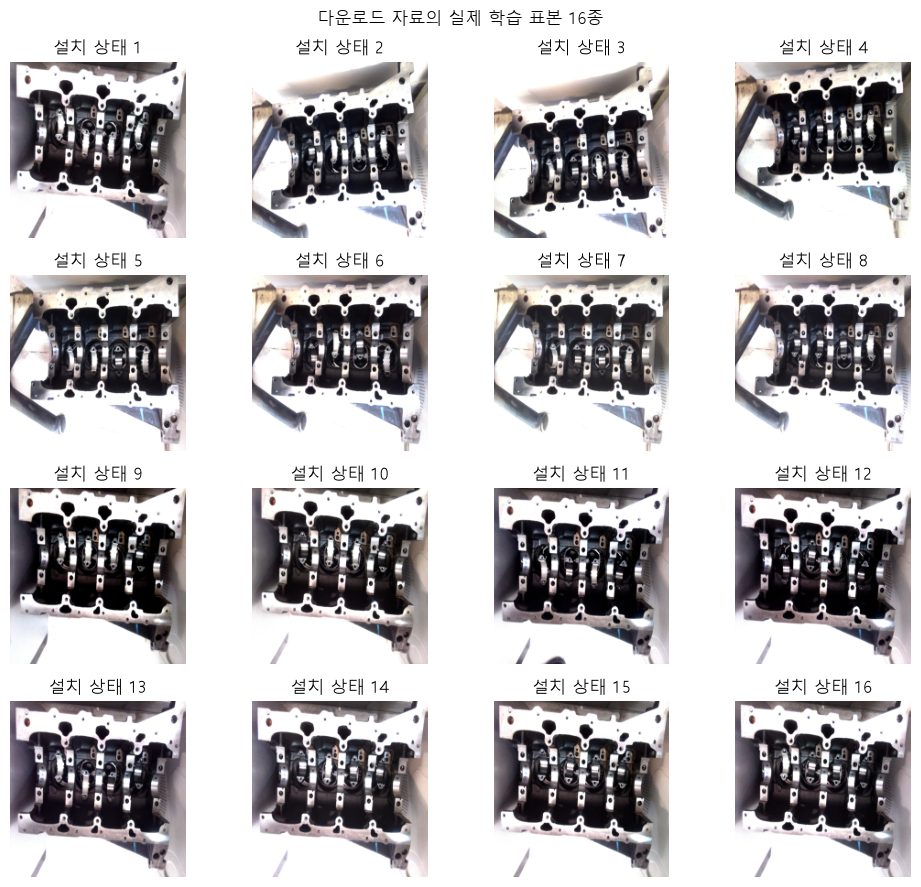

In [6]:
# 큰 원본은 JPEG 축소 디코딩 후 192 입력으로 만든다. 정답 위치를 사용하지 않는다.
def br_read_image(path):
    bgr=cv2.imdecode(np.fromfile(str(path),np.uint8),cv2.IMREAD_REDUCED_COLOR_4)
    if bgr is None:raise ValueError(f"이미지 읽기 실패: {path}")
    rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
    return cv2.resize(rgb,(BR_IMAGE_SIZE,BR_IMAGE_SIZE),interpolation=cv2.INTER_AREA)

br_cache_path=BR_CACHE/f"images_{BR_DATA_SIGNATURE[:16]}.npz"
if br_cache_path.exists():
    with np.load(br_cache_path) as arrays:
        BR_X_TRAIN=arrays["train"];BR_X_VALID=arrays["validation"];BR_X_TEST=arrays["holdout"]
else:
    BR_X_TRAIN=np.stack([br_read_image(path) for path in br_train.path])
    BR_X_VALID=np.stack([br_read_image(path) for path in br_valid.path])
    BR_X_TEST=np.stack([br_read_image(path) for path in br_test.path])
    np.savez_compressed(br_cache_path,train=BR_X_TRAIN,validation=BR_X_VALID,holdout=BR_X_TEST)
BR_Y_TRAIN=br_train.label.to_numpy(dtype="int32")
BR_Y_VALID=br_valid.label.to_numpy(dtype="int32")
BR_Y_TEST=br_test.label.to_numpy(dtype="int32")
print("학습 배열:",BR_X_TRAIN.shape,BR_X_TRAIN.dtype)
fig,axes=plt.subplots(4,4,figsize=(10,9))
for label,ax in enumerate(axes.flat):
    index=int(np.flatnonzero(BR_Y_TRAIN==label)[0])
    ax.imshow(BR_X_TRAIN[index]);ax.set_title(f"설치 상태 {label+1}");ax.axis("off")
fig.suptitle("다운로드 자료의 실제 학습 표본 16종")
plt.tight_layout();plt.savefig(BR_OUT/"figures/training_samples.png",dpi=140);plt.show();plt.close()

### CNN 구성과 학습
기준 모델은 특징 채널 평균(GAP)을 쓴다. 개선 모델은 Flatten으로 어느 위치의 특징인지 보존한다.
네 위치의 설치 조합을 구분하는 문제에서는 위치 정보가 중요하다.
증강 후보도 작은 이동·회전·밝기 변화만 사용하며, 좌우 반전을 하지 않는다.

In [7]:
def build_bearing_cnn(spatial=False,augment=False):
    inputs=keras.Input((BR_IMAGE_SIZE,BR_IMAGE_SIZE,3),name="rgb_uint8")
    x=layers.Rescaling(1.0/255)(inputs)
    if augment:
        x=layers.RandomTranslation(0.06,0.06,fill_mode="reflect",seed=BR_SEED)(x)
        x=layers.RandomRotation(0.025,fill_mode="reflect",seed=BR_SEED)(x)
        x=layers.RandomContrast(0.15,seed=BR_SEED)(x)
    for index,filters in enumerate([16,32,64]):
        x=layers.Conv2D(filters,5 if index==0 else 3,strides=2 if index==0 else 1,
                        padding="same",activation="relu")(x)
        if spatial:
            x=layers.Conv2D(filters,3,padding="same",activation="relu")(x)
        x=layers.MaxPooling2D()(x)
    x=layers.Flatten()(x) if spatial else layers.GlobalAveragePooling2D()(x)
    x=layers.Dense(128 if spatial else 64,activation="relu")(x)
    if spatial:x=layers.Dropout(0.25)(x)
    output=layers.Dense(16,activation="softmax")(x)
    model=keras.Model(inputs,output,name="bearing_spatial" if spatial else "bearing_baseline")
    model.compile(optimizer=keras.optimizers.Adam(0.001 if not spatial else 0.0005),
                  loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return model

class BearingProgress(keras.callbacks.Callback):
    def __init__(self,name):super().__init__();self.name=name
    def on_epoch_end(self,epoch,logs=None):
        save_json(BR_OUT/(self.name+"_progress.json"),dict(model=self.name,epoch=epoch+1,
                  **{key:float(value) for key,value in logs.items()}))

In [8]:
def train_bearing_model(name,spatial=False,augment=False,monitor_accuracy=False):
    path=BR_MODELS/(name+".keras");meta_path=path.with_suffix(".json")
    signature=dict(data=BR_DATA_SIGNATURE,size=BR_IMAGE_SIZE,seed=BR_SEED,
        epochs=BR_EPOCHS,batch_size=BR_BATCH_SIZE,spatial=spatial,augment=augment,version=1)
    if monitor_accuracy:
        signature["checkpoint_monitor"]="val_accuracy"
        signature["early_stopping_patience"]=20
    if augment:
        signature["augmentation"]={"translation":0.06,"rotation":0.025,"contrast":0.15}
    if USE_SAVED_MODELS and path.exists() and meta_path.exists():
        meta=json.loads(meta_path.read_text(encoding="utf-8"))
        if meta["signature"]==signature:
            return keras.models.load_model(path,compile=False),meta
    tf.keras.utils.set_random_seed(BR_SEED)
    model=build_bearing_cnn(spatial,augment)
    counts=np.bincount(BR_Y_TRAIN,minlength=16)
    weights={i:float(np.sqrt(len(BR_Y_TRAIN)/(16*n))) for i,n in enumerate(counts)}
    monitor="val_accuracy" if monitor_accuracy else "val_loss"
    mode="max" if monitor_accuracy else "min"
    patience=20 if monitor_accuracy else 12
    start=time.perf_counter()
    history=model.fit(BR_X_TRAIN,BR_Y_TRAIN,validation_data=(BR_X_VALID,BR_Y_VALID),
        batch_size=BR_BATCH_SIZE,epochs=BR_EPOCHS,class_weight=weights,verbose=2,
        callbacks=[BearingProgress(name),
            keras.callbacks.ModelCheckpoint(str(path),monitor=monitor,mode=mode,save_best_only=True),
            keras.callbacks.EarlyStopping(monitor=monitor,mode=mode,patience=patience,restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss",patience=5,factor=0.5,min_lr=1e-6)])
    model=keras.models.load_model(path,compile=False)
    meta=dict(signature=signature,history={key:[float(v) for v in values] for key,values in history.history.items()},train_seconds=time.perf_counter()-start,
              epochs_run=len(history.history["loss"]),parameters=model.count_params())
    save_json(meta_path,meta)
    return model,meta

def br_plot_history(meta,name):
    fig,axes=plt.subplots(1,2,figsize=(10,3.5))
    for ax,key in zip(axes,["loss","accuracy"]):
        ax.plot(meta["history"][key],label="train")
        ax.plot(meta["history"]["val_"+key],label="validation")
        ax.set(xlabel="Epoch",ylabel=key);ax.legend()
    fig.suptitle(f"{name} | n={len(br_train)}/{len(br_valid)}")
    plt.tight_layout();plt.savefig(BR_OUT/"figures"/(name+"_history.png"),dpi=150)
    plt.show();plt.close()

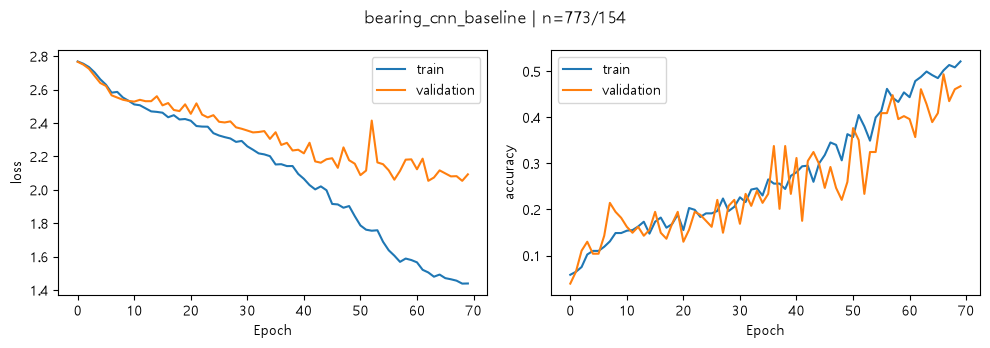

bearing_cnn_baseline 검증 정확도 0.461038961038961


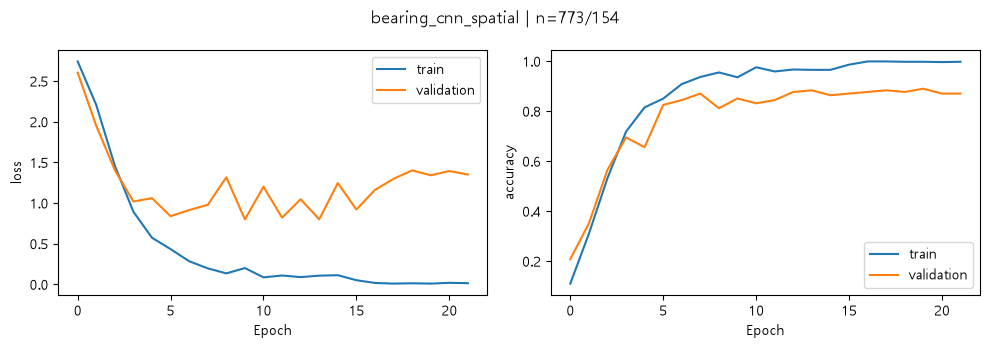

bearing_cnn_spatial 검증 정확도 0.8506493506493507


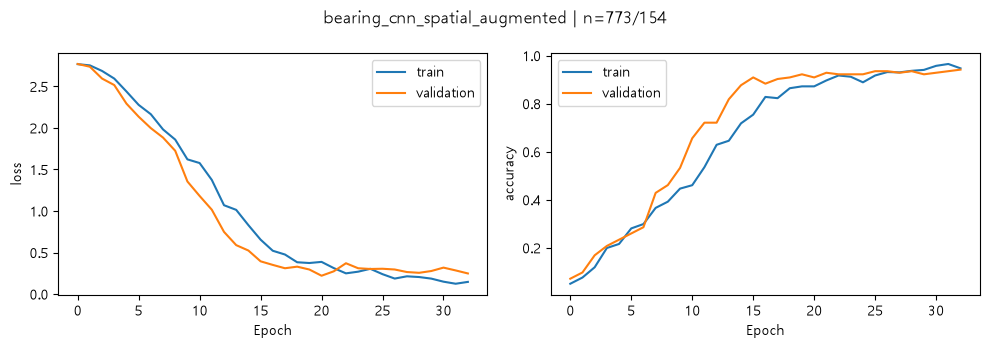

bearing_cnn_spatial_augmented 검증 정확도 0.9090909090909091


Epoch 1/70


25/25 - 14s - loss: 2.7676 - accuracy: 0.0505 - val_loss: 2.7696 - val_accuracy: 0.0714 - lr: 5.0000e-04 - 14s/epoch - 562ms/step


Epoch 2/70


25/25 - 9s - loss: 2.7528 - accuracy: 0.0763 - val_loss: 2.7365 - val_accuracy: 0.0974 - lr: 5.0000e-04 - 9s/epoch - 340ms/step


Epoch 3/70


... (113 outputs left out)

Epoch 60/70


25/25 - 9s - loss: 0.0616 - accuracy: 0.9754 - val_loss: 0.3168 - val_accuracy: 0.9416 - lr: 3.9063e-06 - 9s/epoch - 352ms/step


Epoch 61/70


25/25 - 7s - loss: 0.0953 - accuracy: 0.9690 - val_loss: 0.3104 - val_accuracy: 0.9481 - lr: 3.9063e-06 - 7s/epoch - 260ms/step


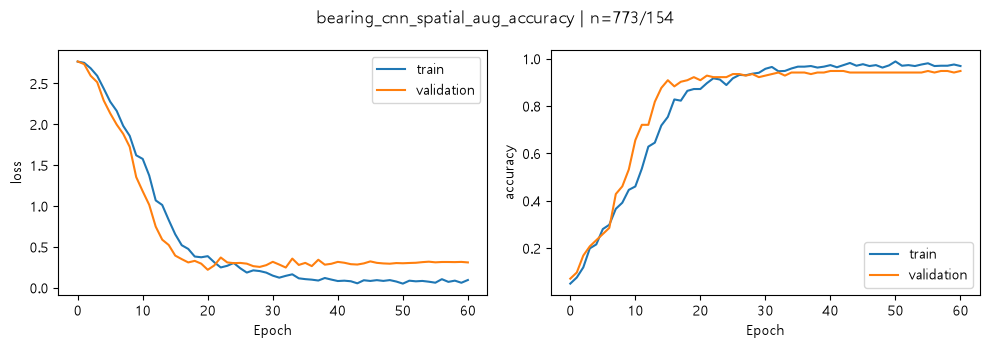

bearing_cnn_spatial_aug_accuracy 검증 정확도 0.948051948051948


,name,validation_accuracy,validation_macro_f1
0,bearing_cnn_baseline,0.461039,0.436500
1,bearing_cnn_spatial,0.850649,0.852177
2,bearing_cnn_spatial_augmented,0.909091,0.898580
3,bearing_cnn_spatial_aug_accuracy,0.948052,0.945294


검증으로 선정: bearing_cnn_spatial_aug_accuracy


In [9]:
# 실행 전에 후보를 고정한다. 모델 선택은 내부 검증 데이터만 사용한다.
BR_PLANS=[dict(name="bearing_cnn_baseline",spatial=False,augment=False),
          dict(name="bearing_cnn_spatial",spatial=True,augment=False),
          dict(name="bearing_cnn_spatial_augmented",spatial=True,augment=True),
          dict(name="bearing_cnn_spatial_aug_accuracy",spatial=True,augment=True,monitor_accuracy=True)]
save_json(BR_OUT/"experiment_plan.json",dict(task="bearing_installation_16class",
    target_accuracy=0.95,run_mode=RUN_MODE,candidates=BR_PLANS,
    max_epochs=BR_EPOCHS,image_size=BR_IMAGE_SIZE,
    selection="validation Macro F1, then accuracy, then fewer parameters",
    holdout="original Classification Validation; duplicates removed; never used for fit"))
br_candidates=[]
for plan in BR_PLANS:
    model,meta=train_bearing_model(**plan)
    probability=model.predict(BR_X_VALID,batch_size=BR_BATCH_SIZE,verbose=0)
    pred=probability.argmax(1)
    result=dict(name=plan["name"],model=model,meta=meta,
        validation_accuracy=float(accuracy_score(BR_Y_VALID,pred)),
        validation_macro_f1=float(f1_score(BR_Y_VALID,pred,labels=range(16),
                                           average="macro",zero_division=0)))
    br_candidates.append(result)
    br_plot_history(meta,plan["name"])
    print(plan["name"],"검증 정확도",result["validation_accuracy"],flush=True)
br_validation_table=pd.DataFrame([{k:c[k] for k in
    ["name","validation_accuracy","validation_macro_f1"]} for c in br_candidates])
display(br_validation_table)
br_validation_table.to_csv(BR_OUT/"validation_comparison.csv",index=False)
br_chosen=max(br_candidates,key=lambda c:(
    c["validation_macro_f1"],c["validation_accuracy"],-c["model"].count_params()))
save_json(BR_OUT/"selection_before_holdout.json",dict(
    selected=br_chosen["name"],validation_accuracy=br_chosen["validation_accuracy"],
    validation_macro_f1=br_chosen["validation_macro_f1"],holdout_used_for_selection=False))
print("검증으로 선정:",br_chosen["name"])

### 최종 홀드아웃 평가
모델을 고정한 뒤 원본 Classification Validation을 최종 평가로 사용한다.
원본 사진 중복은 제거했지만 같은 엔진의 설치 조합 사진이므로 새 엔진/공장 성능을 뜻하지 않는다.
모든 후보의 비교는 선택 이후 기록하며, 평가 점수로 다시 모델을 선택하지 않는다.

,model,accuracy,macro_f1,inference_ms,parameters,train_seconds,selected
0,bearing_cnn_baseline,0.098746,0.075153,1.556662,29552,NaN,False
1,bearing_cnn_spatial,0.288401,0.289480,2.637285,1254688,NaN,False
2,bearing_cnn_spatial_augmented,0.465517,0.455353,4.470577,1254688,259.968061,False
3,bearing_cnn_spatial_aug_accuracy,0.572100,0.555567,4.303325,1254688,511.615857,True


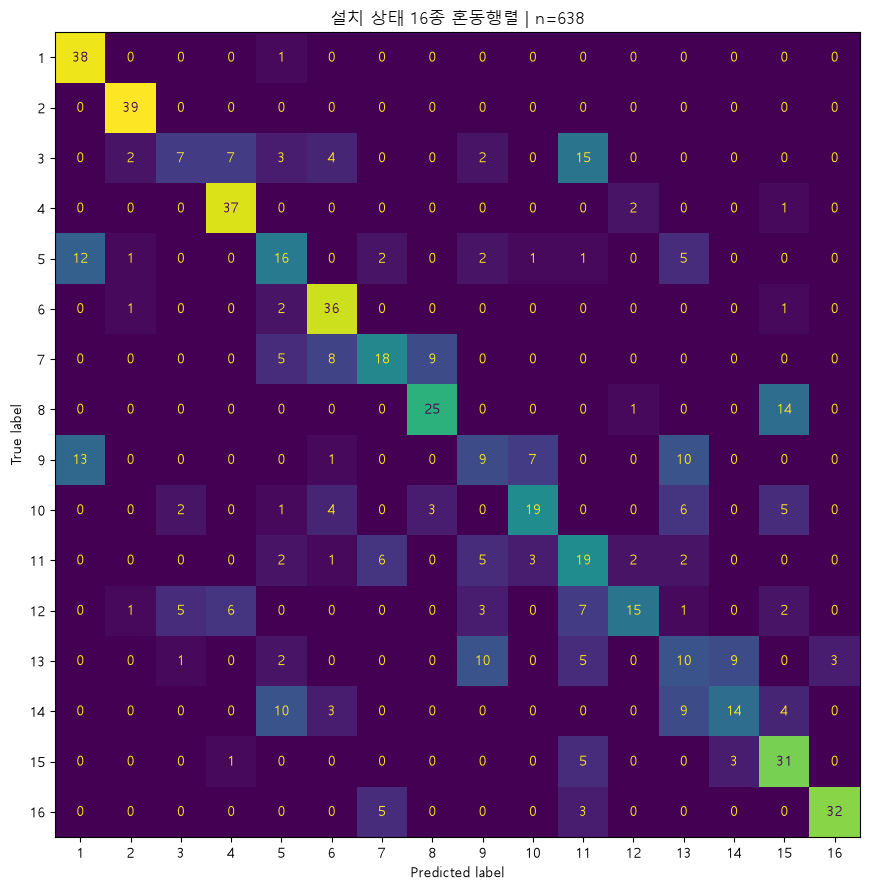

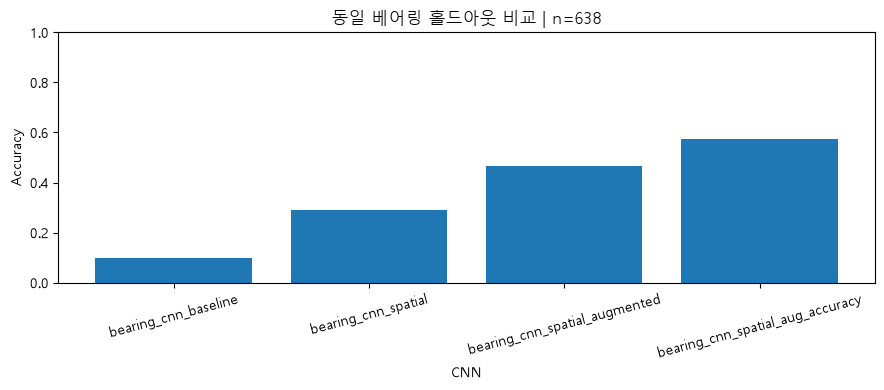

In [10]:
br_test_rows=[]
for candidate in br_candidates:
    model=candidate["model"]
    model(BR_X_TEST[:1],training=False)
    start=time.perf_counter()
    probabilities=model.predict(BR_X_TEST,batch_size=BR_BATCH_SIZE,verbose=0)
    inference_ms=(time.perf_counter()-start)*1000/len(BR_Y_TEST)
    pred=probabilities.argmax(1)
    result=dict(model=candidate["name"],accuracy=float(accuracy_score(BR_Y_TEST,pred)),
        macro_f1=float(f1_score(BR_Y_TEST,pred,labels=range(16),average="macro",zero_division=0)),
        inference_ms=inference_ms,parameters=model.count_params(),
        train_seconds=candidate["meta"]["train_seconds"],
        selected=candidate["name"]==br_chosen["name"])
    br_test_rows.append(result)
    if result["selected"]:
        br_final_probabilities=probabilities
        br_final_pred=pred
        br_final_result=result
br_comparison=pd.DataFrame(br_test_rows)
br_comparison.to_csv(BR_OUT/"holdout_comparison.csv",index=False)
display(br_comparison)
br_class_report=classification_report(BR_Y_TEST,br_final_pred,labels=range(16),
    target_names=BR_CLASS_NAMES,output_dict=True,zero_division=0)
br_metrics=dict(task="bearing_installation_16class",run_mode=RUN_MODE,
    selected_model=br_chosen["name"],train_images=len(br_train),validation_images=len(br_valid),
    evaluation_images=len(br_test),correct=int((br_final_pred==BR_Y_TEST).sum()),
    accuracy=br_final_result["accuracy"],macro_f1=br_final_result["macro_f1"],
    class_report=br_class_report,target_accuracy=0.95,
    target_met=bool(RUN_MODE=="full" and br_final_result["accuracy"]>=0.95),
    binary_quality_supported=False,data_signature=BR_DATA_SIGNATURE,
    limitations=br_audit["limitations"])
save_json(BR_OUT/"metrics.json",br_metrics)
fig,ax=plt.subplots(figsize=(10,9))
ConfusionMatrixDisplay.from_predictions(BR_Y_TEST,br_final_pred,labels=range(16),
    display_labels=BR_CLASS_IDS,ax=ax,colorbar=False)
ax.set_title(f"설치 상태 16종 혼동행렬 | n={len(br_test)}")
plt.tight_layout();plt.savefig(BR_OUT/"figures/confusion_matrix.png",dpi=150);plt.show();plt.close()
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(br_comparison.model,br_comparison.accuracy)
ax.set(ylabel="Accuracy",xlabel="CNN",ylim=(0,1),
       title=f"동일 베어링 홀드아웃 비교 | n={len(br_test)}")
ax.tick_params(axis="x",rotation=15)
plt.tight_layout();plt.savefig(BR_OUT/"figures/model_comparison.png",dpi=150);plt.show();plt.close()

In [11]:
BR_MODEL_VERSION=f"bearing-{RUN_MODE}-{BR_DATA_SIGNATURE[:10]}-{br_chosen['name']}"
br_chosen["model"].save(BR_MODELS/"bearing_cnn_final.keras")
br_config=dict(task="bearing_installation_16class",part_type="ConrodBearing",
    model_name=br_chosen["name"],model_version=BR_MODEL_VERSION,
    model_path=(BR_MODELS/"bearing_cnn_final.keras").relative_to(PROJECT_ROOT).as_posix(),
    input_size=[BR_IMAGE_SIZE,BR_IMAGE_SIZE],channel_order="RGB",
    preprocessing="JPEG reduced-color-4 decode -> RGB -> cv2.INTER_AREA resize; uint8 input",
    normalization="model embeds Rescaling(1/255)",
    output_index_to_class_id={str(i):i+1 for i in range(16)},
    binary_quality_supported=False,normal_defect_mapping=None,
    source_url="https://drive.google.com/file/d/1x1fWg54HHkBc4zABBs3n2Szl6izrwr3n/view",
    original_provider="https://github.com/alireza768/Bearing-Dataset",
    data_signature=BR_DATA_SIGNATURE,limitations=br_audit["limitations"])
save_json(BR_OUT/"model_config.json",br_config)
br_predictions=pd.DataFrame(dict(
    image_id=[f"{row.class_id}/{Path(row.path).name}" for _,row in br_test.iterrows()],
    part_type="ConrodBearing",task="installation_16class",split="holdout",
    class_true=BR_Y_TEST+1,class_pred=br_final_pred+1,
    class_confidence=br_final_probabilities.max(1),model_version=BR_MODEL_VERSION))
for i in range(16):br_predictions[f"prob_class_{i+1}"]=br_final_probabilities[:,i]
br_predictions.to_csv(BR_OUT/"predictions.csv",index=False)
pd.DataFrame(br_class_report).T.to_csv(BR_OUT/"class_report.csv")

In [12]:
_br_predictor=None
def predict_bearing_installation(image):
    global _br_predictor
    if _br_predictor is None:
        config_path=BR_OUT/"model_config.json"
        if not config_path.exists():raise FileNotFoundError("베어링 모델 설정 파일이 없습니다.")
        cfg=json.loads(config_path.read_text(encoding="utf-8"))
        model_path=PROJECT_ROOT/cfg["model_path"]
        if not model_path.exists():raise FileNotFoundError("학습된 베어링 모델이 없습니다.")
        _br_predictor=(cfg,keras.models.load_model(model_path,compile=False))
    cfg,model=_br_predictor
    size=cfg["input_size"][0]
    start=time.perf_counter()
    if isinstance(image,(str,Path)):
        bgr=cv2.imdecode(np.fromfile(str(image),np.uint8),cv2.IMREAD_REDUCED_COLOR_4)
        if bgr is None:raise ValueError("이미지를 읽을 수 없습니다.")
        rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
    else:
        rgb=np.asarray(image)
        if rgb.ndim!=3 or rgb.shape[-1]!=3 or rgb.dtype!=np.uint8:
            raise ValueError("RGB uint8 3채널 배열 또는 파일 경로를 입력하세요.")
    x=cv2.resize(rgb,(size,size),interpolation=cv2.INTER_AREA)[None]
    probability=model(x,training=False).numpy()[0]
    index=int(probability.argmax())
    return dict(task="bearing_installation_16class",part_type="ConrodBearing",
        installation_class=index+1,class_confidence=float(probability[index]),
        class_probabilities={str(i+1):float(p) for i,p in enumerate(probability)},
        binary_quality_status=None,model_version=cfg["model_version"],
        inference_ms=(time.perf_counter()-start)*1000)


In [13]:
br_smoke=predict_bearing_installation(br_test.iloc[0].path)
assert br_smoke["model_version"]==BR_MODEL_VERSION
save_json(BR_OUT/"inference_smoke.json",br_smoke)
display(br_smoke)

{'task': 'bearing_installation_16class',
 'part_type': 'ConrodBearing',
 'installation_class': 1,
 'class_confidence': 0.9999232292175293,
 'class_probabilities': {'1': 0.9999232292175293,
  '2': 4.993070615455508e-05,
  '3': 3.041370746359462e-07,
  '4': 8.240632481948396e-11,
  '5': 2.650725218700245e-05,
  '6': 3.266777959254341e-09,
  '7': 1.1044466730059099e-10,
  '8': 8.371008930246806e-15,
  '9': 4.017347343676647e-09,
  '10': 5.460771279608423e-10,
  '11': 2.8752787911007216e-12,
  '12': 3.071025483750098e-17,
  '13': 5.281186187151843e-13,
  '14': 5.662850018524956e-17,
  '15': 3.949398391558866e-19,
  '16': 3.168957712575966e-17},
 'binary_quality_status': None,
 'model_version': 'bearing-full-2a5a1d481f-bearing_cnn_spatial_aug_accuracy',
 'inference_ms': 67.30080000124872}

In [14]:
import gradio as gr
def br_ui_predict(image):
    if image is None:return "이미지를 입력하세요.",None
    result=predict_bearing_installation(image)
    text=(f"베어링 설치 상태 ID: {result['installation_class']}\n"
          f"분류 점수: {result['class_confidence']:.4f}\n"
          f"추론 시간: {result['inference_ms']:.1f} ms\n"
          "16개 설치 조합 중 분류한 결과입니다. Ring 정상/불량 판정은 지원하지 않습니다.")
    return text,result
with gr.Blocks(title="다운로드 자료 베어링 설치 상태 분류") as bearing_demo:
    gr.Markdown("# 베어링 설치 상태 16종 실제 학습 모델")
    br_image=gr.Image(type="filepath",label="엔진 베어링 설치 사진")
    br_button=gr.Button("설치 상태 분류")
    br_text=gr.Textbox(label="예측",lines=5)
    br_json=gr.JSON(label="실제 모델 결과")
    br_button.click(br_ui_predict,inputs=br_image,outputs=[br_text,br_json],api_name="bearing_installation")
if LAUNCH_BEARING_UI:
    bearing_demo.launch(server_name="127.0.0.1",share=False,inbrowser=False)
else:
    print("LAUNCH_BEARING_UI=True로 지정하고 이 셀을 실행하면 시연 서버가 열립니다.")

C:\Users\kdt66\Desktop\FoldedVision_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LAUNCH_BEARING_UI=True로 지정하고 이 셀을 실행하면 시연 서버가 열립니다.


In [15]:
br_baseline_row=br_comparison[br_comparison.model=="bearing_cnn_baseline"].iloc[0]
br_improvement=br_final_result["accuracy"]-br_baseline_row.accuracy
goal_text="달성" if br_metrics["target_met"] else ("미달" if RUN_MODE=="full" else "quick 점검: 성능 평가 아님")
br_report_text=f'''# 다운로드한 베어링 자료 실제 학습 결과 ({RUN_MODE})

## 결과
실제 베어링 설치 상태 16종 학습과 평가를 수행했다.
기준 CNN 정확도 {br_baseline_row.accuracy:.4%} → 검증 선정 모델 정확도 {br_final_result["accuracy"]:.4%}.
차이: {br_improvement*100:+.2f}%p. 최종 Macro F1 {br_final_result["macro_f1"]:.4f}.
최종 정답 {br_metrics["correct"]}/{len(br_test)}. 베어링 분류 95% 목표: {goal_text}.
최종 모델: {br_chosen["name"]}. 모든 계층을 TensorFlow/Keras로 직접 학습했다.

## 데이터와 분할
다운로드 원본 {len(br_frame)}장. 원본 Train {br_audit["original_train"]}장, 원본 Validation {br_audit["original_validation"]}장.
동일 바이트 중복 초과 {br_audit["exact_duplicate_extra"]}장.
학습 {len(br_train)}장 / 내부 검증 {len(br_valid)}장 / 최종 홀드아웃 {len(br_test)}장.
원본 Validation을 최종 평가로 재지정했다.
동일 SHA 및 같은 클래스 파일명 번호 5장 블록이 분할 사이에 겹치지 않게 했다.
파일 번호 블록은 누수 완화를 위한 가정이며 실제 부품/촬영 세션 ID가 아니다.

## 출처
사용자 제공: {br_config["source_url"]}
원제공자: {br_config["original_provider"]}
원본 ZIP: data/archives/user_oring/Data.zip
정답은 폴더 1~16의 설치 조합 ID다. 정상/불량 또는 O-Ring 결함 라벨로 바꾸지 않았다.

## 수업 기반 개선
기준 CNN의 GAP와 개선 CNN의 Flatten을 동일 분할에서 비교했다.
설치 위치를 보존하고, 작은 이동/회전/대비 증강 후보를 비교했다. 좌우 반전은 하지 않았다.
선정은 검증 Macro F1 → 검증 정확도 → 적은 파라미터 순서로 했다.
홀드아웃 점수를 보고 모델을 다시 고르지 않았다.

## 해석 범위
이 점수는 베어링 설치 상태 16종 분류다. 기존 VISION Ring 3종의 80.95%와 직접 비교할 수 없다.
동일 엔진 장면의 사진이므로 새 엔진·새 공장 성능을 입증하지 않는다.
베어링 설치 ID와 정상/불량 대응표가 없어 정상/불량 Recall이나 불량 감소율은 계산하지 않았다.
기존 Ring 모델·통합 출력은 유지했다.

## 산출물
모델: {br_config["model_path"]}
outputs/bearing_installation의 metrics.json, predictions.csv, model_config.json, class_report.csv.
figures 폴더에 샘플·학습 곡선·혼동행렬·비교 그래프를 저장했다.
predict_bearing_installation(image)와 로컬 Gradio 시연을 포함했다.
검증 기록: validation_checks.json, ui_validation.json, notebook_execution.json.

## 실행 검증과 학습 이력 기록

노트북 full 실행, 4후보 quick 실행, 분할 독립성, 638장 CSV의 정확도·Macro F1 재계산,
기존 Ring 가중치 보존, 학습 데이터 없이 모델·설정 파일만으로 한 예측과 Gradio API 호출을 확인했다.
내부 검증 {br_chosen["validation_accuracy"]:.2%}와 최종 평가 {br_final_result["accuracy"]:.2%}를 구분하며, 내부 검증 점수를 최종 성능으로 제시하지 않는다.

현재 제공된 full 실험의 첫 기준/공간 CNN은 학습과 체크포인트 저장 뒤 이력 JSON의 NumPy float 직렬화 오류가 있었다.
실제 학습 stdout에서 표시된 이력을 복원했으며 그 값은 출력 정밀도로 반올림되어 있다.
체크포인트 가중치는 변경하지 않았고, 확인할 수 없는 학습 시간은 null로 남겼다.
이후 JSON 저장은 Python float 변환으로 수정했고 증강 두 후보는 정상 저장했다.
각 모델 JSON의 history_provenance와 validation_checks.json에 근거를 남겼다.
'''
(BR_OUT/"REPORT.md").write_text(br_report_text,encoding="utf-8")
if RUN_MODE=="full":
    source_path=PROJECT_ROOT/"outputs/user_supplied_links/source_audit.json"
    source_status=json.loads(source_path.read_text(encoding="utf-8"))
    source_status.update(bearing_retraining_performed=True,
        bearing_task="installation_16class",bearing_model_version=BR_MODEL_VERSION,
        bearing_accuracy=br_final_result["accuracy"],bearing_macro_f1=br_final_result["macro_f1"],
        bearing_report="outputs/bearing_installation/REPORT.md",existing_ring_model_preserved=True)
    save_json(source_path,source_status)
print(br_report_text)

# 다운로드한 베어링 자료 실제 학습 결과 (full)

## 결과
실제 베어링 설치 상태 16종 학습과 평가를 수행했다.
기준 CNN 정확도 9.8746% → 검증 선정 모델 정확도 57.2100%.
차이: +47.34%p. 최종 Macro F1 0.5556.
최종 정답 365/638. 베어링 분류 95% 목표: 미달.
최종 모델: bearing_cnn_spatial_aug_accuracy. 모든 계층을 TensorFlow/Keras로 직접 학습했다.

## 데이터와 분할
다운로드 원본 1573장. 원본 Train 933장, 원본 Validation 640장.
동일 바이트 중복 초과 3장.
학습 773장 / 내부 검증 154장 / 최종 홀드아웃 638장.
원본 Validation을 최종 평가로 재지정했다.
동일 SHA 및 같은 클래스 파일명 번호 5장 블록이 분할 사이에 겹치지 않게 했다.
파일 번호 블록은 누수 완화를 위한 가정이며 실제 부품/촬영 세션 ID가 아니다.

## 출처
사용자 제공: https://drive.google.com/file/d/1x1fWg54HHkBc4zABBs3n2Szl6izrwr3n/view
원제공자: https://github.com/alireza768/Bearing-Dataset
원본 ZIP: data/archives/user_oring/Data.zip
정답은 폴더 1~16의 설치 조합 ID다. 정상/불량 또는 O-Ring 결함 라벨로 바꾸지 않았다.

## 수업 기반 개선
기준 CNN의 GAP와 개선 CNN의 Flatten을 동일 분할에서 비교했다.
설치 위치를 보존하고, 작은 이동/회전/대비 증강 후보를 비교했다. 좌우 반전은 하지 않았다.
선정은 검증 Macro F1 → 검증 정확도 → 적은 파라미터 순서로 했다.
홀드아웃 점수를 보고 모델을 다시 고르지 않았다.

## 해석 범위
이 점수는 베어링 설치 상태 16종 분류다. 기존 VISION Ring 3종의 80.95%와 직접 비교할 수 없다.
동일 엔진 장면의 사진이

## 2026-11-23 · Ring / Lens / PCB 추가 학습

[작업 기록 및 평가](outputs/quality_upgrade/REPORT.md)

프로젝트 루트에서 실행합니다. 아래 설정 셀에서 한 작업을 선택합니다. 기본값 `off`는 추가 절 실행을 건너뜁니다.

|설정|동작|
|---|---|
|`ring`|VISION Ring 기존 분할에서 전체·부분 특징 비교|
|`lens`|팀 Lens의 분할과 전처리 재현, 학습용 정상 구역 확장, 구역 CNN 학습|
|`pcb`|VisA PCB1–3 직접 구현 CNN·전이학습 비교와 부분 특징 추가 실험|
|`msdd`|MSDD 원형 금속 가공 부품 결함 유무 분류|
|`infer`|저장 모델에서 `predict_quality_rgb(task, image)` 사용|
|`verify`|저장 가중치 재추론과 웹용 실제 평가 사례 생성|

`infer`에서는 설정, 공통 함수, 추론 셀을 실행합니다. Ring은 결함 유형 점수, Lens는 이미 전처리한 RGB 256×256 구역 점수, PCB와 MSDD는 원본 RGB 이미지 점수를 반환합니다. `q_rgb(path)`로 파일을 읽습니다.

`verify`는 새 실험의 가중치와 각 데이터, 테스트 예측 CSV가 있어야 실행할 수 있습니다.


In [ ]:
# Set one of: off, ring, lens, pcb, msdd, infer, verify.
QUALITY_UPGRADE_STAGE = "off"


In [ ]:
if globals().get("QUALITY_UPGRADE_STAGE", "off") in ('ring', 'lens', 'pcb', 'msdd', 'infer', 'verify'):
    # Quality upgrade setup. Independently executed, keeps all previous training artifacts.
    import os
    os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
    os.environ.setdefault("MPLBACKEND", "Agg")
    from pathlib import Path
    from collections import Counter
    import gc, hashlib, json, shutil, tarfile, time
    import cv2
    import nbformat
    import numpy as np
    import pandas as pd
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                                 confusion_matrix, f1_score, precision_recall_curve, roc_auc_score)

    project_start = Path.cwd().resolve()
    Q_ROOT = next((folder for folder in (project_start, *project_start.parents)
                   if (folder / "requirements-lock.txt").is_file()
                   and (folder / "AGENTS.md").is_file()), None)
    if Q_ROOT is None:
        raise FileNotFoundError("Open this notebook inside the FoldedVision_AI project.")
    Q_DATA = Q_ROOT / "data/external/quality_upgrade"
    Q_ARC = Q_DATA / "source_archives"
    Q_OUT = Q_ROOT / "outputs/quality_upgrade"
    Q_MODELS = Q_ROOT / "models/quality_upgrade"
    for d in (Q_OUT, Q_MODELS):
        d.mkdir(parents=True, exist_ok=True)
    Q_SEED, Q_SIZE = 42, 160
    cv2.setNumThreads(1)
    try:
        tf.config.threading.set_intra_op_parallelism_threads(4)
        tf.config.threading.set_inter_op_parallelism_threads(2)
    except RuntimeError:
        pass
    keras.utils.set_random_seed(Q_SEED)

    def q_hash(path):
        digest = hashlib.sha256()
        with Path(path).open("rb") as stream:
            for block in iter(lambda: stream.read(4 * 1024**2), b""):
                digest.update(block)
        return digest.hexdigest()

    def q_write(path, value):
        path = Path(path)
        temporary = path.with_suffix(path.suffix + ".tmp")
        temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
        temporary.replace(path)

    def q_rgb(path):
        bgr = cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_COLOR)
        if bgr is None:
            raise ValueError(f"Image could not be decoded: {path}")
        return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    def q_resize(image, size=Q_SIZE):
        method = cv2.INTER_AREA if min(image.shape[:2]) >= size else cv2.INTER_LINEAR
        return cv2.resize(image, (size, size), interpolation=method)

    def q_unpack(archive, destination, select):
        """Safely copy only explicit source files. Require all writes to stay within the chosen dataset folder."""
        destination = Path(destination).resolve()
        destination.mkdir(parents=True, exist_ok=True)
        written = 0
        with tarfile.open(archive, "r:*") as package:
            for member in package:
                if not member.isfile():
                    continue
                name = member.name.replace(chr(92), "/").removeprefix("./")
                rel = select(name)
                if rel is None:
                    continue
                target = (destination / rel).resolve()
                if not target.is_relative_to(destination) or ":" in rel or not 0 < member.size <= 50 * 1024**2:
                    raise ValueError(f"Unexpected archive entry: {name}")
                if target.is_file() and target.stat().st_size == member.size:
                    continue
                target.parent.mkdir(parents=True, exist_ok=True)
                partial = target.with_suffix(target.suffix + ".partial")
                with package.extractfile(member) as source, partial.open("wb") as stream:
                    shutil.copyfileobj(source, stream, 1024 * 1024)
                if partial.stat().st_size != member.size:
                    raise IOError(f"Truncated archive member: {name}")
                partial.replace(target)
                written += 1
        return written

    # ImageNet weights are stored locally with their download digest. No hidden download.
    def q_create_encoder():
        q_backbone = keras.applications.MobileNetV2(input_shape=(160, 160, 3), alpha=0.5, include_top=False, weights=None)
        q_backbone.load_weights(Q_ARC / "MobileNetV2_0.5_160.h5")
        q_backbone.trainable = False
        stage_outputs = [q_backbone.get_layer(name).output for name in ("block_6_expand_relu", "block_13_expand_relu", "out_relu")]
        q_act = keras.Model(q_backbone.input, stage_outputs, name="mobilenet_multiscale")
        q_inp = keras.Input(shape=(Q_SIZE, Q_SIZE, 3), dtype="uint8")
        q_stage = q_act(layers.Rescaling(1 / 127.5, offset=-1)(q_inp), training=False)
        q_pool = []
        for feature_map in q_stage:
            q_pool.extend((layers.GlobalAveragePooling2D()(feature_map), layers.GlobalMaxPooling2D()(feature_map)))
        q_encoder = keras.Model(q_inp, layers.Concatenate()(q_pool), name="surface_encoder")
        q_encoder.trainable = False
        return q_encoder

    q_encoder = None

    def q_encode(images, batch_size=48):
        global q_encoder
        if q_encoder is None:
            q_encoder = q_create_encoder()
        arrays = []
        batch = []
        for image in images:
            batch.append(q_resize(image))
            if len(batch) >= batch_size:
                arrays.append(q_encoder(np.stack(batch), training=False).numpy())
                batch = []
        if batch:
            arrays.append(q_encoder(np.stack(batch), training=False).numpy())
        return np.concatenate(arrays).astype(np.float32)

    def q_probs(model, x, batch_size=96):
        return np.concatenate([model(x[i:i + batch_size], training=False).numpy() for i in range(0, len(x), batch_size)])

    def q_binary(y, p, threshold):
        labels = (p >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, labels, labels=[0, 1]).ravel()
        return dict(n=int(len(y)), ap=float(average_precision_score(y, p)), auc=float(roc_auc_score(y, p)),
                    accuracy=float(accuracy_score(y, labels)), f1=float(f1_score(y, labels, zero_division=0)),
                    recall=float(tp / max(1, tp + fn)), fpr=float(fp / max(1, fp + tn)),
                    tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), threshold=float(threshold))

    def q_threshold(y, scores, target_recall=None):
        precision, recall, thresholds = precision_recall_curve(y, scores)
        precision, recall = precision[:-1], recall[:-1]
        if target_recall is not None:
            chosen = np.flatnonzero(recall >= target_recall)
            return float(thresholds[max(chosen, key=lambda i: (precision[i], thresholds[i]))])
        f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-10)
        return float(thresholds[np.argmax(f1)])

    def q_train_head(task, name, x, y, vx, vy, classes, hidden, checkpoint=None):
        """Train an actual Keras head. Use validation loss for early stopping, score candidates only on val."""
        keras.utils.set_random_seed(Q_SEED)
        norm = layers.Normalization(axis=-1, mean=x.mean(axis=0), variance=np.maximum(x.var(axis=0), .0001))
        body = [keras.Input((x.shape[1],)), norm]
        if hidden:
            body.extend([layers.Dense(hidden, activation="relu", kernel_regularizer=keras.regularizers.l2(.0008)), layers.Dropout(.25)])
        body.append(layers.Dense(classes, activation="softmax", kernel_regularizer=keras.regularizers.l2(.001)))
        model = keras.Sequential(body, name=task + "_" + name)
        model.compile(keras.optimizers.Adam(.001 if hidden else .003), "sparse_categorical_crossentropy", metrics=["accuracy"])
        count = np.bincount(y, minlength=classes)
        weights = {i: float(np.sqrt(len(y) / (classes * n))) for i, n in enumerate(count)}
        start = time.monotonic()
        history = model.fit(
            x, y, validation_data=(vx, vy), batch_size=48 if len(y) >= 250 else 12, epochs=55, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)],
            class_weight=weights,
        )
        path = checkpoint if checkpoint else Q_MODELS / f"{task}_{name}_head.keras"
        model.save(path)
        logs = {key: [float(v) for v in values] for key, values in history.history.items()}
        q_write(Q_OUT / f"{task}_{name}_history.json", {"history": logs, "epochs": len(logs["loss"]), "seconds": round(time.monotonic() - start, 2)})
        probs = q_probs(model, vx)
        score = float(average_precision_score(vy, probs[:, 1])) if classes == 2 else float(f1_score(vy, probs.argmax(1), average="macro", labels=np.arange(classes), zero_division=0))
        print(task, name, "epochs", len(logs["loss"]), "validation", score, flush=True)
        return model, score, path.name

    def q_save_combined(task, head):
        result = keras.Model(q_encoder.input, head(q_encoder.output), name=task + "_inference")
        path = Q_MODELS / f"{task}_model.keras"
        result.save(path)
        return path

    def q_labeled_group_split(frame, label="label"):
        """Check content identity and explicitly provided group IDs across splits."""
        assert not frame["path"].duplicated().any()
        assert (frame.groupby("sha256").split.nunique() <= 1).all()
        if "group" in frame:
            assert (frame.groupby("group").split.nunique() <= 1).all()
        return {k: {str(a): int(b) for a, b in v.items()} for k, v in frame.groupby("split")[label].value_counts().unstack(fill_value=0).to_dict("index").items()}

    def q_ring_crops(rgb):
        h, w = rgb.shape[:2]
        return [rgb, rgb[:int(.66*h), :int(.66*w)], rgb[:int(.66*h), int(.34*w):],
                rgb[int(.34*h):, :int(.66*w)], rgb[int(.34*h):, int(.34*w):]]


In [ ]:
if globals().get("QUALITY_UPGRADE_STAGE", "off") in ('ring',):
    # VISION Ring: same original three labels and frozen split.
    ring_manifest = pd.read_csv(Q_ROOT / "outputs/metrics/split_manifest.csv")
    ring_manifest["split"] = ring_manifest.split.replace({"holdout": "test"})
    ring_manifest["path"] = [
        str(Q_ROOT / "data/raw/Ring" / str(phase) / Path(filename).name)
        for phase, filename in zip(ring_manifest.official_split, ring_manifest.path)
    ]
    ring_class = ring_manifest[["label", "defect_type"]].drop_duplicates().sort_values("label").defect_type.tolist()
    assert ring_class == ["t_contamination", "t_scratch", "unfinished_surface"], ring_class
    assert ring_manifest.split.value_counts().to_dict() == {"test": 42, "train": 33, "validation": 12}
    assert all(q_hash(p) == expected for p, expected in zip(ring_manifest.path, ring_manifest.sha256))
    ring_counts = q_labeled_group_split(ring_manifest)

    def q_ring_features(frame):
        features = q_encode(crop for path in frame.path for crop in q_ring_crops(q_rgb(path)))
        features = features.reshape(len(frame), 5, -1)
        tiles = features[:, 1:]
        return {"global": features[:, 0], "global_tiles": np.concatenate(
            [features[:, 0], tiles.mean(axis=1), tiles.max(axis=1)], axis=1
        )}

    ring_frames = {phase: ring_manifest[ring_manifest.split == phase].copy() for phase in ("train", "validation", "test")}
    ring_x = q_ring_features(ring_frames["train"])
    ring_vx = q_ring_features(ring_frames["validation"])
    ring_y, ring_vy = (ring_frames[phase].label.to_numpy() for phase in ("train", "validation"))
    ring_trials = {}
    for ring_view, ring_hidden in (("global", 0), ("global", 48), ("global_tiles", 0), ("global_tiles", 48)):
        trial_name = f"{ring_view}_{ring_hidden or 'linear'}"
        model, score, filename = q_train_head(
            "vision_ring", trial_name, ring_x[ring_view], ring_y, ring_vx[ring_view], ring_vy, 3, ring_hidden
        )
        ring_trials[trial_name] = dict(model=model, score=score, checkpoint=filename, view=ring_view)
    ring_trial_name = max(ring_trials, key=lambda name: ring_trials[name]["score"])
    ring_trial = ring_trials[ring_trial_name]
    ring_test = ring_frames["test"].copy()
    ring_test_prob = q_probs(ring_trial["model"], q_ring_features(ring_test)[ring_trial["view"]])
    ring_test_result = ring_test_prob.argmax(axis=1)
    ring_test["prediction"] = [ring_class[i] for i in ring_test_result]
    for i, label in enumerate(ring_class):
        ring_test["p_" + label] = ring_test_prob[:, i]
    ring_test["path"] = [Path(p).relative_to(Q_ROOT).as_posix() for p in ring_test.path]
    ring_test.to_csv(Q_OUT / "vision_ring_transfer_predictions.csv", index=False, encoding="utf-8-sig")
    q_encoder.save(Q_MODELS / "vision_ring_encoder.keras")
    if ring_trial["view"] == "global":
        q_save_combined("vision_ring", ring_trial["model"])
    ring_test_labels = ring_test.label.to_numpy()
    ring_new_test = dict(
        n=len(ring_test), accuracy=float(accuracy_score(ring_test_labels, ring_test_result)),
        macro_f1=float(f1_score(ring_test_labels, ring_test_result, average="macro", labels=[0, 1, 2], zero_division=0)),
        correct=int((ring_test_labels == ring_test_result).sum()),
        confusion=confusion_matrix(ring_test_labels, ring_test_result, labels=[0, 1, 2]).tolist(),
        per_class=classification_report(ring_test_labels, ring_test_result, labels=[0, 1, 2],
                                        target_names=ring_class, output_dict=True, zero_division=0),
    )
    ring_historical = dict(n=42, correct=34, accuracy=34/42, macro_f1=.5677655677655677)
    ring_report = dict(
        scope="VISION Ring existing same split, three defect types. No verified normal images.",
        split_counts=ring_counts, class_names=ring_class, selected_transfer=ring_trial_name,
        encoder="vision_ring_encoder.keras", head=ring_trial["checkpoint"], feature_views=ring_trial["view"],
        candidates={name: {"validation_macro_f1": row["score"], "checkpoint": row["checkpoint"]} for name, row in ring_trials.items()},
        legacy=ring_historical, test=ring_new_test, input_dtype="uint8 RGB",
        legacy_preserved=True,
    )
    q_write(Q_OUT / "vision_ring_transfer_metrics.json", ring_report)
    print(json.dumps(ring_report), flush=True)


In [ ]:
if globals().get("QUALITY_UPGRADE_STAGE", "off") in ('lens', 'verify'):
    # Lens: preserve the team's full-mode groups and test patches. Expand only training grid negatives.
    import re

    def q_lens_member(name):
        name = name.removeprefix("Lens/")
        return name if re.fullmatch(r"(train|val|inference)/(\d+\.jpg|_annotations\.coco\.json)", name) else None

    lens_root = Q_DATA / "vision_lens"
    files_written = q_unpack(Q_ARC / "Lens.tar.gz", lens_root, q_lens_member)
    print("Lens extracted", files_written, flush=True)
    team_nb = nbformat.read(Q_ROOT / "notebooks/lens/02_Lens_DeepLearning_Final.ipynb", as_version=4)
    lens_workspace = Q_DATA / "lens_workspace"
    lens_workspace.mkdir(exist_ok=True)
    lens_ns = {"__name__": "__main__", "Q_LENS_WORK": lens_workspace, "LENS_DATA_DIR": lens_root}
    for index in (1, 3, 4, 9, 11, 13, 15, 17):
        source = team_nb.cells[index].source.replace("ROOT = Path.cwd().resolve()", "ROOT = Q_LENS_WORK")
        if index == 1:
            os.environ["LENS_RUN_MODE"] = "full"
        exec(compile(source, f"team-lens-cell-{index}", "exec"), lens_ns)
    table = lens_ns["patch_table"]
    work = lens_ns["lens_work"]
    pad = lens_ns["pad_to"]
    patch_size = lens_ns["PATCH"]
    original_counts = {}
    lens_split = {}
    for phase in ("train", "validation", "test"):
        original = table[(table.split == phase) & table.use]
        original_counts[phase] = [int(len(original)), int(original.label.sum())]
        selection = original
        if phase == "train":
            selection = table[(table.split == phase) & (table.label >= 0)].drop_duplicates(["image_key", "y", "x"])
        lens_split[phase] = selection.reset_index(drop=True)
    assert original_counts == {"train": [2277, 759], "validation": [806, 141], "test": [3410, 579]}, original_counts
    for before, after in (("train", "validation"), ("train", "test"), ("validation", "test")):
        assert set(lens_split[before].image_key).isdisjoint(lens_split[after].image_key)
    print("Lens train after expansion", lens_split["train"].label.value_counts().to_dict(), flush=True)

    def q_lens_patches(rows):
        prepared = {key: pad(work[key]["image"]) for key in rows.image_key.unique()}
        for row in rows.itertuples():
            yield prepared[row.image_key][row.y:row.y + patch_size, row.x:row.x + patch_size]


In [ ]:
if globals().get("QUALITY_UPGRADE_STAGE", "off") in ('lens',):
    # Train and evaluate the patch candidates after Lens data preparation.
    lens_train, lens_val = (lens_split[phase] for phase in ("train", "validation"))
    lens_x = q_encode(q_lens_patches(lens_train))
    lens_vx = q_encode(q_lens_patches(lens_val))
    lens_y, lens_vy = lens_train.label.to_numpy(), lens_val.label.to_numpy()
    lens_candidates = {}
    for name, hidden in (("linear", 0), ("dense96", 96)):
        model, score, filename = q_train_head("lens_patch", name, lens_x, lens_y, lens_vx, lens_vy, 2, hidden)
        lens_candidates[name] = (model, score, filename)
    lens_name = max(lens_candidates, key=lambda name: lens_candidates[name][1])
    lens_head = lens_candidates[lens_name][0]
    lens_validation_prob = q_probs(lens_head, lens_vx)[:, 1]
    lens_threshold = q_threshold(lens_vy, lens_validation_prob, target_recall=.95)
    lens_test = lens_split["test"].copy()
    lens_test_prob = q_probs(lens_head, q_encode(q_lens_patches(lens_test)))[:, 1]
    lens_test["p_defect_patch"] = lens_test_prob
    lens_test["predicted_label"] = (lens_test_prob >= lens_threshold).astype(int)
    lens_test.to_csv(Q_OUT / "lens_patch_predictions.csv", index=False, encoding="utf-8-sig")
    lens_path = q_save_combined("lens_patch", lens_head)
    lens_test_metrics = q_binary(lens_test.label.to_numpy(), lens_test_prob, lens_threshold)
    lens_report = dict(
        scope="VISION Lens grid patch classification. Test has 52 defective whole images, no verified normal whole images.",
        data_images={phase: int(rows.image_key.nunique()) for phase, rows in lens_split.items()},
        patch_counts={phase: {"total": int(len(rows)), "defect": int(rows.label.sum())} for phase, rows in lens_split.items()},
        original_patch_counts=original_counts, checkpoint=lens_path.name, selected=lens_name,
        candidate_validation_ap={name: v[1] for name, v in lens_candidates.items()},
        legacy=dict(ap=.418667, auc=.755983, recall=.920553, fpr=.654186),
        validation=q_binary(lens_vy, lens_validation_prob, lens_threshold), test=lens_test_metrics,
        whole_image_defect_detection_count=int(lens_test.groupby("image_key").predicted_label.max().sum()),
        original_patch_px=int(patch_size), input_shape=[160, 160, 3], input_dtype="uint8 RGB",
    )
    q_write(Q_OUT / "lens_patch_metrics.json", lens_report)
    print(json.dumps(lens_report), flush=True)


In [ ]:
if globals().get("QUALITY_UPGRADE_STAGE", "off") in ('pcb',):
    # PCB1-3: separate VisA high-shot binary benchmark. PCB4 YOLO remains a distinct localization project.
    pcb_source = pd.read_csv(Q_ARC / "VisA_2cls_highshot.csv")
    pcb_boards = ["pcb1", "pcb2", "pcb3"]
    pcb_frame = pcb_source[pcb_source.object.isin(pcb_boards)].copy()
    pcb_path_set = set(pcb_frame.image)
    pcb_root = Q_DATA / "visa_highshot_pcb123"
    new_images = q_unpack(Q_ARC / "VisA_20220922.tar", pcb_root, lambda name: name if name in pcb_path_set else None)
    missing_images = [path for path in pcb_path_set if not (pcb_root / path).is_file()]
    assert not missing_images, missing_images[:10]
    print("PCB images extracted", new_images, "required", len(pcb_path_set), flush=True)
    pcb_frame = pcb_frame.rename(columns={"split": "official_split", "label": "official_label"})
    pcb_frame["label"] = pcb_frame.official_label.map({"normal": 0, "anomaly": 1}).astype(int)
    pcb_frame["path"] = [str(pcb_root / path) for path in pcb_frame.image]
    pcb_frame["sha256"] = [q_hash(path) for path in pcb_frame.path]
    pcb_frame["split"] = pcb_frame.official_split
    pcb_train_groups = pcb_frame[pcb_frame.official_split == "train"].groupby(["object", "label"])
    for _, rows in pcb_train_groups:
        selected_ids = rows.sample(n=int(round(len(rows) * .20)), random_state=Q_SEED).index
        pcb_frame.loc[selected_ids, "split"] = "validation"
    pcb_frame["priority"] = pcb_frame.split.map({"test": 0, "validation": 1, "train": 2})
    pcb_frame = pcb_frame.sort_values(["priority", "image"])
    pcb_duplicates = pcb_frame[pcb_frame.sha256.duplicated(keep=False)].copy()
    assert (pcb_duplicates.groupby("sha256").label.nunique() <= 1).all(), "Conflicting duplicate labels"
    pcb_excluded = int(pcb_frame.sha256.duplicated().sum())
    pcb_frame = pcb_frame.drop_duplicates("sha256").drop(columns="priority")
    pcb_counts = q_labeled_group_split(pcb_frame)
    for split, rows in pcb_frame.groupby("split"):
        print("PCB", split, rows.groupby(["object", "label"]).size().to_dict(), flush=True)
    pcb_export = pcb_frame.copy().drop(columns="path")
    pcb_export["local_image"] = ["data/external/quality_upgrade/visa_highshot_pcb123/" + path for path in pcb_export.image]
    pcb_export.to_csv(Q_OUT / "pcb_visA_split.csv", index=False, encoding="utf-8-sig")
    pcb_splits = {phase: pcb_frame[pcb_frame.split == phase].copy() for phase in ("train", "validation", "test")}
    pcb_train, pcb_validate = [pcb_splits[phase] for phase in ("train", "validation")]
    pcb_y, pcb_vy = pcb_train.label.to_numpy(), pcb_validate.label.to_numpy()
    pcb_native_size = 96

    def q_pcb_arrays(rows, size):
        return np.stack([q_resize(q_rgb(path), size) for path in rows.path])

    def q_compact_cnn(name, size):
        inp = keras.Input((size, size, 3), dtype="uint8")
        x = layers.Rescaling(1 / 255)(inp)
        for filters in (16, 32, 64):
            x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
            x = layers.MaxPooling2D()(x)
        x = layers.Concatenate()([layers.GlobalAveragePooling2D()(x), layers.GlobalMaxPooling2D()(x)])
        x = layers.Dropout(.25)(layers.Dense(32, activation="relu")(x))
        return keras.Model(inp, layers.Dense(2, activation="softmax")(x), name=name)

    keras.utils.set_random_seed(Q_SEED)
    pcb_cnn = q_compact_cnn("pcb_native_cnn", pcb_native_size)
    pcb_cnn.compile(keras.optimizers.Adam(.001), "sparse_categorical_crossentropy", metrics=["accuracy"])
    pcb_native_x = q_pcb_arrays(pcb_train, pcb_native_size)
    pcb_native_vx = q_pcb_arrays(pcb_validate, pcb_native_size)
    pcb_train_class_counts = np.bincount(pcb_y)
    pcb_weights = {i: float(np.sqrt(len(pcb_y) / (2 * n))) for i, n in enumerate(pcb_train_class_counts)}
    start = time.monotonic()
    pcb_cnn_history = pcb_cnn.fit(
        pcb_native_x, pcb_y, validation_data=(pcb_native_vx, pcb_vy), class_weight=pcb_weights,
        batch_size=48, epochs=20, verbose=2,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
    ).history
    pcb_cnn.save(Q_MODELS / "pcb_native_cnn.keras")
    q_write(Q_OUT / "pcb_native_history.json", dict(
        history={k: [float(v) for v in values] for k, values in pcb_cnn_history.items()},
        epochs=len(pcb_cnn_history["loss"]), seconds=round(time.monotonic() - start, 2)
    ))
    pcb_native_val = q_probs(pcb_cnn, pcb_native_vx)[:, 1]
    pcb_models = {"native": (float(average_precision_score(pcb_vy, pcb_native_val)), pcb_native_val, pcb_cnn)}
    del pcb_native_x, pcb_native_vx
    gc.collect()
    pcb_x = q_encode(q_rgb(path) for path in pcb_train.path)
    pcb_vx = q_encode(q_rgb(path) for path in pcb_validate.path)
    for name, hidden in (("linear", 0), ("dense96", 96)):
        head, ap, filename = q_train_head("pcb_transfer", name, pcb_x, pcb_y, pcb_vx, pcb_vy, 2, hidden)
        pcb_models[name] = (ap, q_probs(head, pcb_vx)[:, 1], head)
    pcb_selected = max(pcb_models, key=lambda name: pcb_models[name][0])
    _, pcb_val_prob, pcb_model = pcb_models[pcb_selected]
    pcb_threshold = q_threshold(pcb_vy, pcb_val_prob)
    pcb_test = pcb_splits["test"]
    if pcb_selected == "native":
        pcb_test_prob = q_probs(pcb_model, q_pcb_arrays(pcb_test, pcb_native_size))[:, 1]
        pcb_saved = "pcb_native_cnn.keras"
        pcb_size = pcb_native_size
    else:
        pcb_test_prob = q_probs(pcb_model, q_encode(q_rgb(path) for path in pcb_test.path))[:, 1]
        pcb_saved = q_save_combined("pcb_visa", pcb_model).name
        pcb_size = Q_SIZE
    pcb_test["anomaly_score"] = pcb_test_prob
    pcb_test["predicted_label"] = (pcb_test_prob >= pcb_threshold).astype(int)
    pcb_test.drop(columns="path").to_csv(Q_OUT / "pcb_visa_predictions.csv", index=False, encoding="utf-8-sig")
    pcb_report = dict(
        scope="VisA PCB1-PCB3 whole-image normal/anomaly classification; excludes PCB4 and does not localize.",
        split_counts=pcb_counts, board_counts={board: q_labeled_group_split(rows) for board, rows in pcb_frame.groupby("object")},
        validation_rule="20% of the official training set per board and class, seed 42; select by AP, threshold by F1",
        exact_duplicates_excluded=pcb_excluded, checkpoint=pcb_saved, selected=pcb_selected,
        candidate_validation_ap={name: result[0] for name, result in pcb_models.items()},
        validation=q_binary(pcb_vy, pcb_val_prob, pcb_threshold),
        test=q_binary(pcb_test.label.to_numpy(), pcb_test_prob, pcb_threshold),
        test_by_board={board: q_binary(rows.label.to_numpy(), rows.anomaly_score.to_numpy(), pcb_threshold)
                       for board, rows in pcb_test.groupby("object")},
        input_shape=[pcb_size, pcb_size, 3], input_dtype="uint8 RGB",
    )
    q_write(Q_OUT / "pcb_visa_metrics.json", pcb_report)
    print(json.dumps(pcb_report), flush=True)


In [ ]:
if globals().get("QUALITY_UPGRADE_STAGE", "off") in ('pcb',):
    # Compare higher-detail PCB views against the completed whole-image experiment.
    # Selection uses the same validation rows; the same published test is a reused benchmark.
    pcb_prior = json.loads((Q_OUT / "pcb_visa_metrics.json").read_text(encoding="utf-8"))
    pcb_manifest = pd.read_csv(Q_OUT / "pcb_visA_split.csv")
    pcb_frames = {phase: pcb_manifest[pcb_manifest.split == phase].copy() for phase in ("train", "validation", "test")}
    assert [len(pcb_frames[phase]) for phase in ("train", "validation", "test")] == [1590, 397, 1324]

    def q_pcb_detail_features(rows):
        encoded = q_encode(crop for path in rows.local_image for crop in q_ring_crops(q_rgb(Q_ROOT / path)))
        encoded = encoded.reshape(len(rows), 5, -1)
        tiles = encoded[:, 1:]
        return np.concatenate([encoded[:, 0], tiles.mean(axis=1), tiles.max(axis=1)], axis=1)

    pcb_train, pcb_val = (pcb_frames[name] for name in ("train", "validation"))
    px, pvx = q_pcb_detail_features(pcb_train), q_pcb_detail_features(pcb_val)
    py, pvy = pcb_train.label.to_numpy(), pcb_val.label.to_numpy()
    pcb_detail_trials = {}
    for name, hidden in (("linear", 0), ("dense96", 96)):
        model, ap, filename = q_train_head("pcb_detail", name, px, py, pvx, pvy, 2, hidden)
        pcb_detail_trials[name] = (model, ap, filename)
    pcb_detail_name = max(pcb_detail_trials, key=lambda name: pcb_detail_trials[name][1])
    detail_model, detail_val_ap, detail_checkpoint = pcb_detail_trials[pcb_detail_name]
    pcb_comparison = {
        "global_best_validation_ap": max(pcb_prior["candidate_validation_ap"].values()),
        "detail_best_validation_ap": detail_val_ap,
        "detail_candidates_validation_ap": {name: entry[1] for name, entry in pcb_detail_trials.items()},
        "test_reuse": "The same published test rows were already evaluated for the whole-image experiment. Follow-up is a benchmark comparison.",
    }
    if detail_val_ap > pcb_comparison["global_best_validation_ap"]:
        pcb_val_prob = q_probs(detail_model, pvx)[:, 1]
        pcb_thr = q_threshold(pvy, pcb_val_prob)
        pcb_detail_test = pcb_frames["test"].copy()
        pcb_detail_test["anomaly_score"] = q_probs(detail_model, q_pcb_detail_features(pcb_detail_test))[:, 1]
        pcb_detail_test["predicted_label"] = (pcb_detail_test.anomaly_score >= pcb_thr).astype(int)
        pcb_detail_test.to_csv(Q_OUT / "pcb_detail_predictions.csv", index=False, encoding="utf-8-sig")
        detail_encoder = Q_MODELS / "pcb_detail_encoder.keras"
        q_encoder.save(detail_encoder)
        detail_test = q_binary(pcb_detail_test.label.to_numpy(), pcb_detail_test.anomaly_score.to_numpy(), pcb_thr)
        pcb_detail_report = dict(pcb_prior)
        pcb_detail_report.update(
            scope="VisA PCB1-PCB3 photo classification from the whole image and four overlapping crops; independent of PCB4 YOLO.",
            selected="detail_" + pcb_detail_name, checkpoint=detail_checkpoint, encoder=detail_encoder.name,
            feature_views="global_tiles", comparison=pcb_comparison,
            candidate_validation_ap={**pcb_prior["candidate_validation_ap"], **{
                "detail_" + name: entry[1] for name, entry in pcb_detail_trials.items()
            }},
            validation=q_binary(pvy, pcb_val_prob, pcb_thr), test=detail_test,
            test_by_board={board: q_binary(rows.label.to_numpy(), rows.anomaly_score.to_numpy(), pcb_thr)
                          for board, rows in pcb_detail_test.groupby("object")},
            global_test=pcb_prior["test"],
        )
        q_write(Q_OUT / "pcb_detail_metrics.json", pcb_detail_report)
        pcb_comparison["record"] = "pcb_detail_metrics.json"
    else:
        pcb_comparison["record"] = "pcb_visa_metrics.json"
    q_write(Q_OUT / "pcb_selection.json", pcb_comparison)
    print(json.dumps(pcb_comparison), flush=True)


In [ ]:
if globals().get("QUALITY_UPGRADE_STAGE", "off") in ('msdd',):
    # MSDD is a related circular machined metal dataset, evaluated separately from VISION Ring.
    msdd_root = Q_DATA / "msdd_grouped"
    msdd = pd.read_csv(msdd_root / "meta.csv").rename(columns={"part": "group"})
    msdd["disk_split"] = msdd.split
    msdd["split"] = msdd.split.replace({"val": "validation"})
    msdd["path"] = [str(msdd_root / "images" / phase / image) for phase, image in zip(msdd.disk_split, msdd.image)]
    msdd["annotation"] = [str(msdd_root / "labels" / phase / Path(image).with_suffix(".txt")) for phase, image in zip(msdd.disk_split, msdd.image)]
    assert all(Path(path).is_file() for path in msdd.path)
    assert all(Path(path).is_file() for path in msdd.annotation)
    assert msdd.split.value_counts().to_dict() == {"train": 1195, "validation": 150, "test": 150}
    msdd_lines = [Path(path).read_text(encoding="utf-8-sig").strip().splitlines() for path in msdd.annotation]
    assert (np.array([len(lines) for lines in msdd_lines]) == msdd.n_defects).all()
    msdd["label"] = [int(bool(lines)) for lines in msdd_lines]
    msdd["sha256"] = [q_hash(path) for path in msdd.path]
    msdd_counts = q_labeled_group_split(msdd)
    ring_digest = set(pd.read_csv(Q_ROOT / "outputs/metrics/image_inventory.csv").sha256.dropna())
    assert not set(msdd.sha256).intersection(ring_digest)
    msdd_groups = {phase: int(count) for phase, count in msdd.groupby("split").group.nunique().items()}
    assert msdd_groups == {"test": 30, "train": 239, "validation": 30}
    msdd_export = msdd.drop(columns=["disk_split"]).copy()
    for name in ("path", "annotation"):
        msdd_export[name] = [Path(p).relative_to(Q_ROOT).as_posix() for p in msdd_export[name]]
    msdd_export.to_csv(Q_OUT / "msdd_split.csv", index=False, encoding="utf-8-sig")
    msdd_splits = {phase: msdd[msdd.split == phase].copy() for phase in ("train", "validation", "test")}
    msdd_train, msdd_val = [msdd_splits[x] for x in ("train", "validation")]
    msdd_x = q_encode(q_rgb(p) for p in msdd_train.path)
    msdd_vx = q_encode(q_rgb(p) for p in msdd_val.path)
    msdd_y, msdd_vy = msdd_train.label.to_numpy(), msdd_val.label.to_numpy()
    msdd_trials = {}
    for name, hidden in (("linear", 0), ("dense96", 96)):
        model, _, _ = q_train_head("msdd", name, msdd_x, msdd_y, msdd_vx, msdd_vy, 2, hidden)
        probs = q_probs(model, msdd_vx)[:, 1]
        balanced_ap = .5 * (average_precision_score(msdd_vy, probs) + average_precision_score(1 - msdd_vy, 1 - probs))
        msdd_trials[name] = (model, probs, float(balanced_ap))
    msdd_selected = max(msdd_trials, key=lambda name: msdd_trials[name][2])
    msdd_model, msdd_vprob, _ = msdd_trials[msdd_selected]
    from sklearn.metrics import roc_curve
    msdd_fpr, msdd_tpr, msdd_thresholds = roc_curve(msdd_vy, msdd_vprob)
    msdd_threshold = float(msdd_thresholds[1 + np.argmax(msdd_tpr[1:] - msdd_fpr[1:])])
    msdd_test = msdd_splits["test"]
    msdd_test_prob = q_probs(msdd_model, q_encode(q_rgb(p) for p in msdd_test.path))[:, 1]
    msdd_pred = msdd_test.assign(defect_score=msdd_test_prob, predicted_label=(msdd_test_prob >= msdd_threshold).astype(int))
    msdd_pred.drop(columns=["path", "annotation", "disk_split"]).to_csv(Q_OUT / "msdd_predictions.csv", index=False, encoding="utf-8-sig")

    def q_msdd_metrics(y, probs):
        record = q_binary(y, probs, msdd_threshold)
        record["normal_ap"] = float(average_precision_score(1 - y, 1 - probs))
        record["balanced_accuracy"] = (record["recall"] + 1 - record["fpr"]) / 2
        return record

    msdd_saved = q_save_combined("msdd", msdd_model)
    msdd_report = dict(
        scope="MSDD round machined metal images, any annotated defect versus empty annotation. Separate from VISION Ring.",
        split_counts=msdd_counts, part_groups=msdd_groups, same_vision_ring_bytes=0,
        selected=msdd_selected, candidate_validation_mean_ap={name: row[2] for name, row in msdd_trials.items()},
        checkpoint=msdd_saved.name, validation=q_msdd_metrics(msdd_vy, msdd_vprob),
        test=q_msdd_metrics(msdd_test.label.to_numpy(), msdd_test_prob),
        input_shape=[160, 160, 3], input_dtype="uint8 RGB",
    )
    q_write(Q_OUT / "msdd_metrics.json", msdd_report)
    print(json.dumps(msdd_report), flush=True)


In [ ]:
if globals().get("QUALITY_UPGRADE_STAGE", "off") in ('infer', 'verify'):
    # Opt-in inference APIs for the saved experiments. Input is RGB uint8.
    from functools import lru_cache

    @lru_cache(maxsize=None)
    def q_read_metric(task):
        names = {"ring": "vision_ring_transfer", "lens": "lens_patch", "pcb": "pcb_visa", "msdd": "msdd"}
        name = names[task] + "_metrics.json"
        if task == "pcb":
            name = json.loads((Q_OUT / "pcb_selection.json").read_text(encoding="utf-8"))["record"]
        return json.loads((Q_OUT / name).read_text(encoding="utf-8"))

    @lru_cache(maxsize=None)
    def q_load_checkpoint(filename):
        return keras.models.load_model(Q_MODELS / filename, compile=False)

    def predict_quality_rgb(task, image):
        """Ring type, Lens patch, PCB1-3 whole image, or separate MSDD image. Outputs include model scores."""
        rgb = np.asarray(image)
        if rgb.ndim != 3 or rgb.shape[-1] != 3 or min(rgb.shape[:2]) < 2 or rgb.dtype != np.uint8:
            raise ValueError("Expected a nonempty RGB uint8 image of shape (height, width, 3).")
        metric = q_read_metric(task)
        if "encoder" in metric:
            encoder = q_load_checkpoint(metric["encoder"])
            head = q_load_checkpoint(metric["head"] if task == "ring" else metric["checkpoint"])
            inputs = np.stack([q_resize(crop) for crop in q_ring_crops(rgb)])
            features = encoder(inputs, training=False).numpy()
            x = features[:1]
            if metric["feature_views"] == "global_tiles":
                tiles = features[1:]
                x = np.concatenate([x, tiles.mean(axis=0, keepdims=True), tiles.max(axis=0, keepdims=True)], axis=1)
            scores = head(x, training=False).numpy()[0]
            if task == "ring":
                classes = metric["class_names"]
                return {"status": "REVIEW", "class": classes[int(scores.argmax())],
                        "scores": {name: float(score) for name, score in zip(classes, scores)}}
            score = float(scores[1])
        else:
            if task == "lens" and rgb.shape[:2] != (metric["original_patch_px"],) * 2:
                raise ValueError("Lens expects one prepared 256 x 256 RGB patch after scaling the original lens.")
            model = q_load_checkpoint(metric["checkpoint"])
            resized = q_resize(rgb, metric["input_shape"][0])
            score = float(model(resized[None], training=False).numpy()[0, 1])
        threshold = metric["validation"]["threshold"]
        return {"status": "REVIEW", "score": score, "label": int(score >= threshold), "threshold": threshold,
                "unit": "patch" if task == "lens" else "image"}


In [ ]:
if globals().get("QUALITY_UPGRADE_STAGE", "off") in ('verify',):
    # Recompute scores from the saved checkpoints and package actual holdout examples for the local portfolio.
    quality_artifacts = {}
    quality_cases = {}
    quality_site = Q_ROOT / "sites/foldedvision-inspection"
    quality_media = quality_site / "public/evidence/quality"
    quality_media.mkdir(parents=True, exist_ok=True)

    def q_check_replay(task, image, expected):
        replay = predict_quality_rgb(task, image)
        scores = list(replay["scores"].values()) if task == "ring" else replay["score"]
        error = float(np.max(np.abs(np.asarray(scores) - np.asarray(expected))))
        assert error < .0002, (task, error)
        return error

    def q_case_media(task, role, image):
        h, w = image.shape[:2]
        factor = min(1, 560 / max(h, w))
        thumbnail = cv2.resize(image, (round(w * factor), round(h * factor)), interpolation=cv2.INTER_AREA)
        ok, encoded = cv2.imencode(".webp", cv2.cvtColor(thumbnail, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_WEBP_QUALITY, 88])
        assert ok
        fn = f"{task}-{role}.webp"
        encoded.tofile(str(quality_media / fn))
        return f"./evidence/quality/{fn}"

    def q_get_csv(name):
        return pd.read_csv(Q_OUT / (name + "_predictions.csv"), encoding="utf-8-sig")

    ring_csv = q_get_csv("vision_ring_transfer")
    ring_metric = q_read_metric("ring")
    assert len(ring_csv) == 42
    assert (ring_csv.prediction == ring_csv.defect_type).sum() == ring_metric["test"]["correct"]
    ring_columns = ["p_" + name for name in ring_metric["class_names"]]
    ring_errors = [q_check_replay("ring", q_rgb(Q_ROOT / row.path), [getattr(row, c) for c in ring_columns])
                   for row in ring_csv.head(9).itertuples()]
    quality_artifacts["ring"] = {"records": len(ring_csv), "replayed": len(ring_errors), "max_score_delta": max(ring_errors)}
    ring_cases = []
    for role, row in (
        ("hit", ring_csv[(ring_csv.defect_type == "unfinished_surface") & (ring_csv.prediction == ring_csv.defect_type)].iloc[0]),
        ("error", ring_csv[ring_csv.prediction != ring_csv.defect_type].iloc[0]),
    ):
        ring_cases.append(dict(role=role, truth=row.defect_type, prediction=row.prediction,
                               score=float(row["p_" + row.prediction]), sample=row.image_id,
                               src=q_case_media("ring", role, q_rgb(Q_ROOT / row.path))))
    quality_cases["ring"] = ring_cases

    pcb_record = json.loads((Q_OUT / "pcb_selection.json").read_text(encoding="utf-8"))["record"]
    pcb_predictions = pcb_record.removesuffix("_metrics.json")
    binary_jobs = (
        ("lens", "lens_patch", "p_defect_patch", q_lens_patches),
        ("pcb", pcb_predictions, "anomaly_score", lambda rows: (q_rgb(Q_DATA / "visa_highshot_pcb123" / path) for path in rows.image)),
        ("msdd", "msdd", "defect_score", lambda rows: (q_rgb(Q_DATA / "msdd_grouped/images/test" / filename) for filename in rows.image)),
    )
    for task, file, score_column, images_for in binary_jobs:
        frame = q_get_csv(file)
        metric = q_read_metric(task)
        recomputed = q_binary(frame.label.to_numpy(), frame[score_column].to_numpy(), metric["validation"]["threshold"])
        assert all(np.isclose(float(recomputed[k]), float(metric["test"][k])) for k in recomputed)
        # Replay clean and defective examples plus the errors where present.
        replay = frame.groupby(["label", "predicted_label"]).head(3)
        errors = [q_check_replay(task, image, score) for image, score in zip(images_for(replay), replay[score_column])]
        quality_artifacts[task] = {"records": len(frame), "replayed": len(errors), "max_score_delta": max(errors)}
        if task == "msdd":
            continue
        task_cases = []
        for role, pool in (
            ("hit", frame[(frame.label == 1) & (frame.predicted_label == 1)]),
            ("error", frame[frame.label != frame.predicted_label]),
        ):
            if pool.empty:
                continue
            row = pool.head(1)
            current = row.iloc[0]
            sample = (f"{current.image_key} ({current.x}, {current.y})" if task == "lens" else str(current.image))
            task_cases.append(dict(role=role, truth=int(current.label), prediction=int(current.predicted_label),
                                   score=float(current[score_column]), sample=sample,
                                   src=q_case_media(task, role, next(images_for(row)))))
        quality_cases[task] = task_cases

    q_write(Q_OUT / "inference_replay.json", quality_artifacts)
    q_write(quality_site / "src/qualityResults.json", {
        "date": "2026-11-23", "ring": q_read_metric("ring"), "lens": q_read_metric("lens"),
        "pcb": q_read_metric("pcb"), "msdd": q_read_metric("msdd"), "cases": quality_cases,
    })
    print(json.dumps(quality_artifacts), flush=True)
